# Matrix elements, one GEVP basis and one set of fit parameters per pz

Run the cells from top to bottom. Sections 2b and 6b ask before they save a fit: answer `y` to save, anything else saves nothing.

Order: 0 settings and GEVP basis, 1 GEVP, 2a 2pt fit, 2b save it, 3 3pt, 4 ratio, 5 ratio fit, 6a check the fit, 6b save it, 7 single and double ratios.

## 0. Settings: the GEVP basis of each pz

In [1]:
import os
import time
import h5py
import numpy as np
import matplotlib.pyplot as plt
import gvar as gv
import lsqfit

#hadron, kinematics definition
hadron = "pion"              #"pion" or "proton"
frame = "forward"            #"forward" or "sym"
q = (0,0,0)                  #the q of a cell that does not average over q;  forward: (0,0,0);  sym: (2,0,0), (-2,0,0), (0,2,0) or (0,-2,0)
project = True               #proton only: True = positive-parity files, False = open Dirac files; For now, no opec dirac proton data, to be done later

#the data: every data set of this list is read, and they are joined along the cfg axis in this order;  to use one data set only, take the other one out of the list
#  "dir": its folder;  "ncfg": the number of cfgs in the names of its 2pt files;  "ff_ncfg": the number of cfgs in the names of its FF files
#  "cfg_shift": added to its cfg numbers, so that the cfg numbers of two streams stay apart
#the Frontier folder has pion files only: for the proton take the frontier_stream_d entry out
data_sets = [{"name": "delta_stream_e", "dir": "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta", "ncfg": 585, "ff_ncfg": 800, "cfg_shift": 0},
             {"name": "frontier_stream_d", "dir": "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_frontier_streamd", "ncfg": 200, "ff_ncfg": 798, "cfg_shift": 100000}]
ncfg = 0                     #the total number of cfgs: it goes in the names of the saved files
for data in data_sets:
    ncfg = ncfg + data["ncfg"]
Lt = 96
Ls = 32
hyp = 8                      #hyp steps to be used

#Here a tricky thing which turns out to be harmless
#<3pt>=<2ptFF>-<2pt><FF>, but for off-forward case, where does e^-iqxsrc go in the vacuum term.
#For "2pt", it's <2pt*e^-iqxsrc><FF>, by translation invariance, the first term is extremely close to zero but not zero
#For "FF",  it's <2pt><FF*e^-iqxsrc>, which is exactly zero for off-forwawrd case
phase_attached_to = "2pt"     #choose between "2pt" & "FF"


#the GEVP of each pz, used by all the cells below:  "basis" = its operators, "t0" = GEVP reference time, "t_ref" = time of the ground-state vector v0
#an operator is smear + gamma:  smear B = [4.5,2.25,0.8], U = [1.5,1.5,0];  gamma G5, G5G4, G3G5
pion_default = {0: {"basis": ["BG5G4", "UG5", "UG5G4"], "t0": 3, "t_ref": 5},
                1: {"basis": ["UG5", "UG5G4"], "t0": 3, "t_ref": 5},
                2: {"basis": ["BG5", "UG5G4", "UG3G5"], "t0": 3, "t_ref": 5},
                3: {"basis": ["UG3G5"], "t0": 3, "t_ref": 5},
                4: {"basis": ["UG3G5"], "t0": 3, "t_ref": 5},
                5: {"basis": ["BG5G4", "UG5G4"], "t0": 3, "t_ref": 5},
                6: {"basis": ["BG3G5", "UG3G5"], "t0": 3, "t_ref": 5}}
proton_default = {0: {"basis": ["UG5", "UG5G4"], "t0": 3, "t_ref": 5},
                  1: {"basis": ["UG5", "UG5G4"], "t0": 3, "t_ref": 5},
                  2: {"basis": ["UG5G4", "UG3G5"], "t0": 3, "t_ref": 5},
                  3: {"basis": ["UG5G4", "UG3G5"], "t0": 3, "t_ref": 5},
                  4: {"basis": ["UG5G4", "UG3G5"], "t0": 3, "t_ref": 5},
                  5: {"basis": ["UG5G4"], "t0": 3, "t_ref": 5},
                  6: {"basis": ["BG3G5"], "t0": 3, "t_ref": 5}}
#the choice the cells below use, and its name:  everything goes in the folder AI_assisted_matrix_element_analysis/{gevp_tag}
#to try another choice, give it a new gevp_tag: a folder keeps the choice it was first made with
if hadron == "pion":
    gevp_choice = pion_default
    gevp_tag = "pion_default"
else:
    gevp_choice = proton_default
    gevp_tag = "proton_default"
op_basis = [(0,0),(0,1),(0,2),(1,0),(1,1),(1,2)]    #the six operators of the files, (smear, gamma):  smear 0 = B, 1 = U;  gamma 0 = G5, 1 = G5G4, 2 = G3G5
smear_names = ["B", "U"]
gamma_names = ["G5", "G5G4", "G3G5"]
op_labels = [smear_names[s] + gamma_names[g] for s, g in op_basis]     #["BG5", "BG5G4", ...]

#directories and names
analysis_dir = "/Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/AI_assisted_matrix_element_analysis"
save_dir = os.path.join(analysis_dir, gevp_tag)
#the names of the files inside the folder of a data set
#C3input: q-phase averaged in;  C2pf, C2pi: no q-phase averaged in;  at q = 0 the C3input file is also the C2pf and the C2pi file
pt2_name = "2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_{frame}_q{qx}_{qy}_{qz}_{pt2_type}_fb_tsep20_3072src_ncfg{ncfg}_{hadron}.h5"
ff_name = "FF_hyp0-8_w0-9_q{qx}_{qy}_{qz}_ncfg{ncfg}.h5"


assert frame in ["forward", "sym"], f"frame = {frame}: use forward or sym"
if frame == "forward":
    q_list = [(0,0,0)]
else:
    q_list = [(2,0,0), (-2,0,0), (0,2,0), (0,-2,0)]
q = tuple(q)
assert q in q_list, f"frame = {frame} with q = {q}: use one of {q_list}"
for pz in gevp_choice:
    assert gevp_choice[pz]["t_ref"] > gevp_choice[pz]["t0"], f"pz = {pz}: t_ref has to be larger than t0"
    for name in gevp_choice[pz]["basis"]:
        assert name in op_labels, f"pz = {pz}: {name} is not one of {op_labels}"

if hadron == "pion":
    hadron_tag = "pion"
elif project:
    hadron_tag = "proton_projected"
else:
    hadron_tag = "proton"
c_sign = {"pion": -1, "proton": +1}[hadron]      #to make Cij positive definite, the pion is multiplied by -1


#======== functions used by several cells ========
def pt2_file(data, q_i, pt2_type):
    #the 2pt file of one data set of data_sets
    return os.path.join(data["dir"], pt2_name.format(frame=frame, qx=q_i[0], qy=q_i[1], qz=q_i[2], pt2_type=pt2_type, ncfg=data["ncfg"], hadron=hadron_tag))


def read_joined(q_i, pt2_type, name):
    #one dataset of the 2pt files that has an entry per cfg, e.g. "pt2_forward", "t_src_list", "cfg_list":  read from every data set and joined along the cfg axis
    parts = []
    for data in data_sets:
        file = pt2_file(data, q_i, pt2_type)
        assert os.path.exists(file), f"no such file: {file}"
        with h5py.File(file, "r") as f:
            part = f[name][()]
        assert part.shape[0] == data["ncfg"], f"{file}: {part.shape[0]} cfgs, but data_sets says {data['ncfg']}"
        if name == "cfg_list":
            part = part + data["cfg_shift"]     #the cfg numbers of two streams stay apart
        parts.append(part)
    return np.concatenate(parts)


def read_shared(q_i, pt2_type, name):
    #one dataset of the 2pt files that has to be the same in every data set, e.g. "pz_list", "pf_list", "smear_list"
    for data in data_sets:
        file = pt2_file(data, q_i, pt2_type)
        assert os.path.exists(file), f"no such file: {file}"
        with h5py.File(file, "r") as f:
            value = f[name][()]
        if data is data_sets[0]:
            first = value
        assert np.array_equal(value, first), f"{name} of {data['name']} is not the same as in {data_sets[0]['name']}"
    return first


def jk(data, jk_axis=0):
    #jackknife mean and error
    n = data.shape[jk_axis]
    data = np.moveaxis(data, jk_axis, 0)
    mean = np.mean(data, axis=0)
    err = np.sqrt((n - 1.0) / n * np.sum((data - mean) ** 2, axis=0))
    return mean, err


def jackknife(x):
    #per-cfg data (cfg, ...) -> jackknife samples (jk, ...)
    n_cfg = x.shape[0]
    return (x.sum(axis=0) - x) / (n_cfg - 1)


def read_pt2(q_i, pt2_type):
    #both halves of the packed 2pt files, the data sets joined: (cfg, smear, smear, gamma, gamma, t_src, pz, tsep)
    for data in data_sets:
        print("reading", pt2_file(data, q_i, pt2_type))
    return read_joined(q_i, pt2_type, "pt2_forward"), read_joined(q_i, pt2_type, "pt2_backward")


def solve_gevp(C_matrix, t0_pz):
    #one pz:  C_matrix (op, op, tsep): eigenvalues (state, tsep) and eigenvectors (state, tsep, op), largest eigenvalue first, NaN at tsep <= t0_pz
    n_op, _, n_tsep = C_matrix.shape
    eigen_val = np.full((n_op, n_tsep), np.nan)
    eigen_vec = np.full((n_op, n_tsep, n_op), np.nan, dtype=complex)
    L_inv = np.linalg.inv(np.linalg.cholesky(C_matrix[:, :, t0_pz]))
    for t in range(t0_pz + 1, n_tsep):
        M = L_inv @ C_matrix[:, :, t] @ L_inv.conj().T
        w, u = np.linalg.eigh(M)
        v = L_inv.conj().T @ u
        order = np.argsort(w)[::-1]
        eigen_val[:, t] = w[order]
        eigen_vec[:, t] = v[:, order].T
    return eigen_val, eigen_vec


def save_gevp_info(f, basis):
    #what every saved file states about the data sets and the GEVP;  f is an open h5py file
    f["data_sets"] = [data["name"] for data in data_sets]                   #(set,): the data sets that were joined, in this order
    f["data_set_ncfg"] = [data["ncfg"] for data in data_sets]               #(set,)
    f["data_set_cfg_shift"] = [data["cfg_shift"] for data in data_sets]     #(set,): what was added to the cfg numbers of each set in cfg_list
    f["gevp_tag"] = gevp_tag
    f["gevp_basis"] = [" ".join(gevp_choice[pz]["basis"]) for pz in gevp_choice]    #(pz,): the operators of each pz in words
    f["op_basis"] = basis               #(op, 2): (smear, gamma) indices of smear_names, gamma_names
    f["smear_names"] = smear_names
    f["smear_list"] = smear_list
    f["gamma_names"] = gamma_names
    f["t0"] = [gevp_choice[pz]["t0"] for pz in gevp_choice]         #(pz,)
    f["t_ref"] = [gevp_choice[pz]["t_ref"] for pz in gevp_choice]   #(pz,)


def op_matrix(pt2, basis):
    #(cfg, smear_snk, smear_src, gamma_snk, gamma_src, ...) -> (cfg, op_snk, op_src, ...)
    n_op = len(basis)
    Cij = np.zeros(pt2.shape[:1] + (n_op, n_op) + pt2.shape[5:], dtype=complex)
    for a, (s_snk, g_snk) in enumerate(basis):
        for b, (s_src, g_src) in enumerate(basis):
            Cij[:, a, b] = pt2[:, s_snk, s_src, g_snk, g_src]
    return Cij


def apply_v0(Cij, v):
    #v^dagger C v:  Cij (cfg, op, op, ..., pz, tsep), v (pz, op) -> (cfg, ..., pz, tsep)
    return c_sign * np.einsum("pa,cab...pT,pb->c...pT", v.conj(), Cij, v)


def pt3_path(q_i):
    #the 3pt file of the basis of this cell at one q
    q_tag_i = f"q{q_i[0]}_{q_i[1]}_{q_i[2]}"
    if frame == "forward":
        folder = "forward"
    else:
        folder = f"sym_{q_tag_i}"
    return os.path.join(save_dir, "3pt_data", folder, f"3pt_{frame}_{q_tag_i}_{gevp_tag}_phase{phase_attached_to}_hyp{hyp}_ncfg{ncfg}_{hadron_tag}.h5")


def pt2_fit_path(frame_i, q_tag_i, subfolder_i, half):
    #the saved 2pt fit: one file, replaced when you save again;  what the fit used is written inside the file
    return os.path.join(save_dir, "2pt_fit_data", subfolder_i, f"2pt_fit_{frame_i}_{q_tag_i}_{gevp_tag}_{half}_ncfg{ncfg}_{hadron_tag}.h5")


def ratio_fit_path(frame_i, q_tag_i, subfolder_i, half, pz):
    #the saved ratio fit of one pz: one file per pz, replaced when you save that pz again;  what the fit used is written inside the file
    return os.path.join(save_dir, "ratio_fit_data", subfolder_i, f"ratio_fit_{frame_i}_{q_tag_i}_{gevp_tag}_phase{phase_attached_to}_{half}_hyp{hyp}_ncfg{ncfg}_{hadron_tag}_pz{pz}.h5")


gevp_file = os.path.join(save_dir, "2pt_gevp_data", frame, f"2pt_gevp_{frame}_{gevp_tag}_ncfg{ncfg}_{hadron_tag}.h5")

#---- the data sets: every file is there, the smearings agree, and no cfg number appears twice
smear_list = read_shared(q, "C3input", "smear_list")        #(smear, 3): rho_T, rho_z, boost fraction
all_cfg = read_joined(q, "C3input", "cfg_list")             #(cfg,): the joined cfg numbers, cfg_shift added
assert len(np.unique(all_cfg)) == len(all_cfg), "two data sets have a cfg number in common: give one of them another cfg_shift"
for data in data_sets:
    print(f"data set {data['name']}: {data['ncfg']} cfg, cfg numbers + {data['cfg_shift']}, folder {data['dir']}")

#---- the folder of this choice:  another gevp_choice with the same gevp_tag stops here, so two choices cannot get mixed in one folder
choice_text = ""
for pz in gevp_choice:
    choice_text = choice_text + f"pz {pz}: {' '.join(gevp_choice[pz]['basis'])}, t0 {gevp_choice[pz]['t0']}, t_ref {gevp_choice[pz]['t_ref']}\n"
os.makedirs(save_dir, exist_ok=True)
choice_file = os.path.join(save_dir, "gevp_choice.txt")
if not os.path.exists(choice_file):
    with open(choice_file, "w") as f:
        f.write(choice_text)
with open(choice_file, "r") as f:
    assert f.read() == choice_text, f"{choice_file} holds another gevp_choice:  change gevp_tag, or set gevp_choice back"
print("hadron", hadron_tag, "| frame", frame, "| q", q, "|", ncfg, "cfg in total")
print("GEVP choice", gevp_tag, "| folder", save_dir)
print(choice_text)

data set delta_stream_e: 585 cfg, cfg numbers + 0, folder /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta
data set frontier_stream_d: 200 cfg, cfg numbers + 100000, folder /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_frontier_streamd
hadron pion | frame forward | q (0, 0, 0) | 785 cfg in total
GEVP choice pion_default | folder /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/AI_assisted_matrix_element_analysis/pion_default
pz 0: BG5G4 UG5 UG5G4, t0 3, t_ref 5
pz 1: UG5 UG5G4, t0 3, t_ref 5
pz 2: BG5 UG5G4 UG3G5, t0 3, t_ref 5
pz 3: UG3G5, t0 3, t_ref 5
pz 4: UG3G5, t0 3, t_ref 5
pz 5: BG5G4 UG5G4, t0 3, t_ref 5
pz 6: BG3G5 UG3G5, t0 3, t_ref 5



## 1. GEVP: the reconstructed 2pt

In [2]:
#======== GEVP: reconstruct 2pt with the choice of section 0 and save on disk ========
#every pz has its own operators, t0 and t_ref;  v0 is saved with all six operators, 0 for the ones this pz does not use

#---- read the 2pt of every q and average over t_src
if frame == "forward":
    pt2_type = "C3input"        #at q = 0 this file is also C2pf and C2pi
else:
    pt2_type = "C2pf"           #C2pi(q) is exactly C2pf(-q), so the C2pi files are not needed

half_list = ["forward", "backward"]
C2_raw = {"forward": [], "backward": []}    #C2_raw[half][iq]: (cfg, smear, smear, gamma, gamma, pz, tsep)
pf_list = []                                #pf_list[iq]: (pz, 3), the momentum of each 2pt
for q_i in q_list:
    raw_forward, raw_backward = read_pt2(q_i, pt2_type)
    assert raw_forward.ndim == 8, "the GEVP needs (cfg, smear, smear, gamma, gamma, t_src, pz, tsep): open Dirac files have to be projected first"
    C2_raw["forward"].append(raw_forward.mean(axis=5))  #here averaged over tsrc
    C2_raw["backward"].append(raw_backward.mean(axis=5))
    pf_list.append(read_shared(q_i, pt2_type, "pf_list"))
    pz_list = read_shared(q_i, pt2_type, "pz_list")
    if q_i == q_list[0]:
        cfg_list = read_joined(q_i, pt2_type, "cfg_list")       #(cfg,): the cfgs of all data sets
    assert np.array_equal(read_joined(q_i, pt2_type, "cfg_list"), cfg_list), f"q = {q_i}: other cfgs than the first q"
assert list(gevp_choice) == list(pz_list), f"gevp_choice has to have every pz of the files, in order: {list(pz_list)}"

n_cfg = C2_raw["forward"][0].shape[0]
n_pz = C2_raw["forward"][0].shape[5]
n_tsep = C2_raw["forward"][0].shape[6]
n_q = len(q_list)
n_all = len(op_basis)

#---- every half, q and pz: solve the GEVP on the operators of this pz, reconstruct the 2pt
C2_rec = {}
v0 = {}
eigen_val = {}
for half in half_list:
    C2_rec[half] = np.zeros((n_cfg, n_q, n_pz, n_tsep), dtype=complex)      #(cfg, q, pz, tsep)
    v0[half] = np.zeros((n_q, n_pz, n_all), dtype=complex)                  #(q, pz, op), all six operators
    eigen_val[half] = np.full((n_q, n_pz, n_all, n_tsep), np.nan)           #(q, pz, state, tsep), NaN for the states this pz does not have
    for iq, q_i in enumerate(q_list):
        iq_minus = q_list.index((-q_i[0], -q_i[1], -q_i[2]))
        C_plus = op_matrix(C2_raw[half][iq], op_basis)                      #(cfg, op, op, pz, tsep), +q (q/2,0,pz)
        C_minus = op_matrix(C2_raw[half][iq_minus], op_basis)               #(cfg, op, op, pz, tsep), -q (-q/2,0,pz)
        #gevp problem was solved for [C2(q) + C2(-q)] / 2, hermitianized: (op, op, pz, tsep)
        C_mean = c_sign * 0.5 * (C_plus + C_minus).mean(axis=0)
        C_mean = 0.5 * (C_mean + C_mean.conj().swapaxes(0, 1))
        for ipz, pz in enumerate(pz_list):
            use = [op_labels.index(name) for name in gevp_choice[pz]["basis"]]     #which of the six operators this pz uses
            C_use = C_mean[np.ix_(use, use)][:, :, ipz]                     #(n_use, n_use, tsep)
            val, vec = solve_gevp(C_use, gevp_choice[pz]["t0"])             #val (state, tsep), vec (state, tsep, op);  state 0 is the ground state
            eigen_val[half][iq, ipz, :len(use)] = val
            v0[half][iq, ipz, use] = vec[0, gevp_choice[pz]["t_ref"]]
        C2_rec[half][:, iq] = apply_v0(C_plus, v0[half][iq])

#---- save
os.makedirs(os.path.dirname(gevp_file), exist_ok=True)
with h5py.File(gevp_file, "w") as f:
    for half in half_list:
        f[f"C2_{half}"] = C2_rec[half]              #(cfg, q, pz, tsep), complex, c_sign already in;  q in the order of q_list
        f[f"v0_{half}"] = v0[half]                  #(q, pz, op), all six operators
        f[f"eigen_val_{half}"] = eigen_val[half]    #(q, pz, state, tsep), NaN at tsep <= t0
    f["q_list"] = q_list                            #(q, 3)
    f["pf_list"] = np.array(pf_list)                #(q, pz, 3): the momentum of C2
    f["pz_list"] = pz_list
    f["cfg_list"] = cfg_list
    save_gevp_info(f, op_basis)
print("saved", gevp_file)

reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_forward_q0_0_0_C3input_fb_tsep20_3072src_ncfg585_pion.h5
reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_frontier_streamd/2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_forward_q0_0_0_C3input_fb_tsep20_3072src_ncfg200_pion.h5
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/AI_assisted_matrix_element_analysis/pion_default/2pt_gevp_data/forward/2pt_gevp_forward_pion_default_ncfg785_pion.h5


## 2a. 2pt fit: result and effective-mass plots

GEVP choice pion_default
---- pz = 0, BG5G4 UG5 UG5G4: the fit of the jackknife mean
Least Squares Fit:
  chi2/dof [dof] = 0.71 [14]    Q = 0.77    logGBF = 71.085

Parameters:
             E0   0.14100 (11)      [   0.14 (20) ]  
            c 0    1.5057 (18)      [ 0 ± 1.0e+04 ]  
              1      0.02 (12)      [ 0 ± 1.0e+04 ]  
              2      1.55 (48)      [ 0 ± 1.0e+04 ]  
      log(dE) 0     -0.3 (1.0)      [  -1.4 (1.6) ]  
              1     -0.30 (76)      [  -1.4 (1.6) ]  
---------------------------------------------------
           dE 0      0.74 (75)      [   0.25 (40) ]  
              1      0.74 (56)      [   0.25 (40) ]  

Settings:
  svdcut/n = 1e-07/0    tol = (1e-08,1e-10,1e-10*)    (itns/time = 90/0.0s)
  fitter = scipy_least_squares    method = trf

---- pz = 1, UG5 UG5G4: the fit of the jackknife mean
Least Squares Fit:
  chi2/dof [dof] = 0.44 [13]    Q = 0.96    logGBF = 67.027

Parameters:
             E0   0.24164 (21)      [   0.24 (20) ]  
    

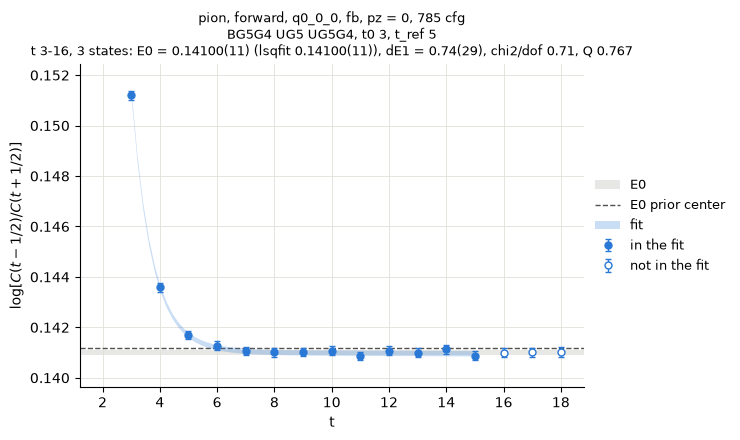

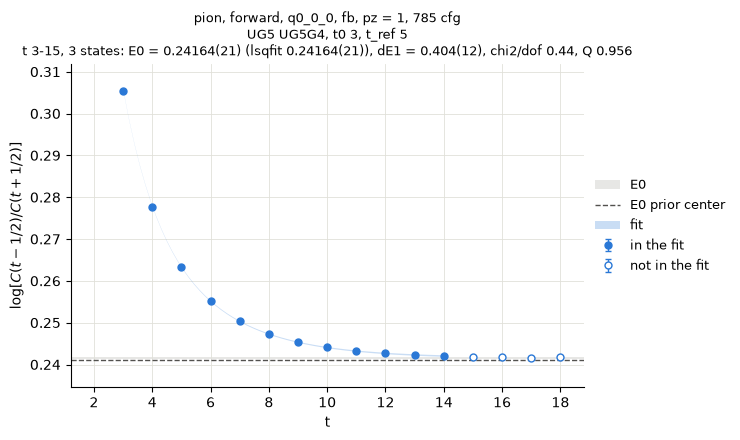

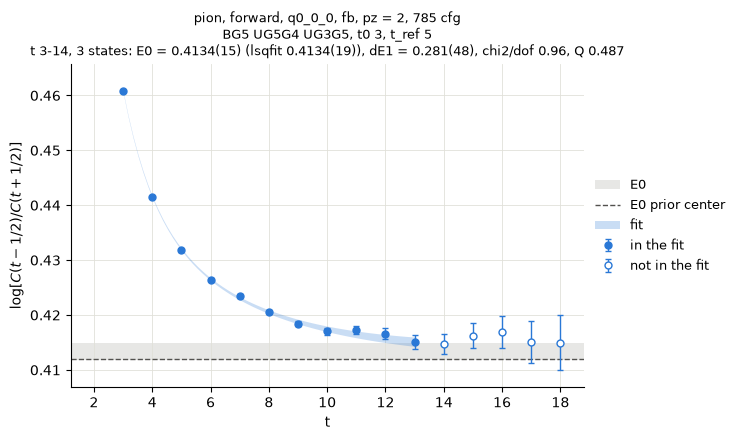

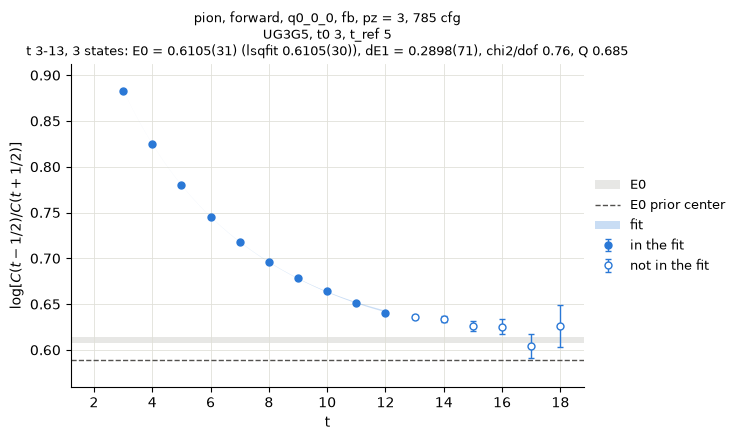

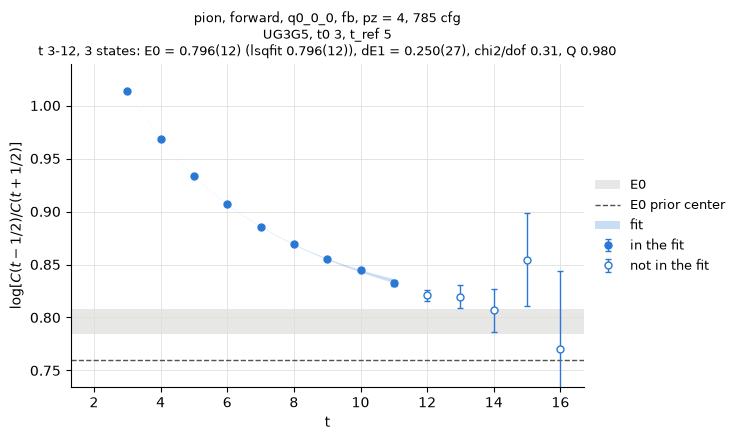

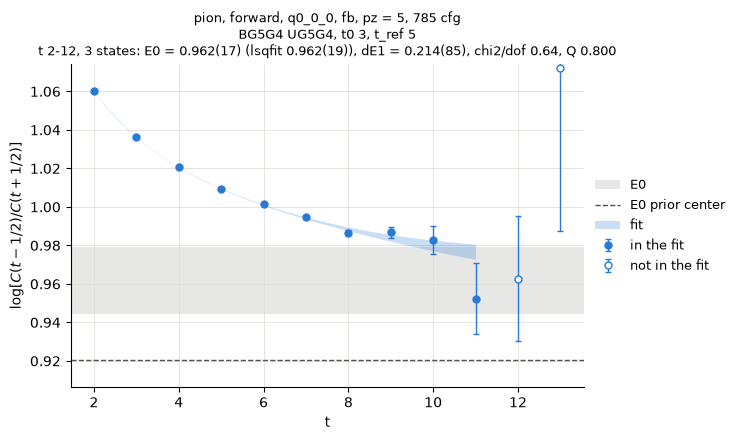

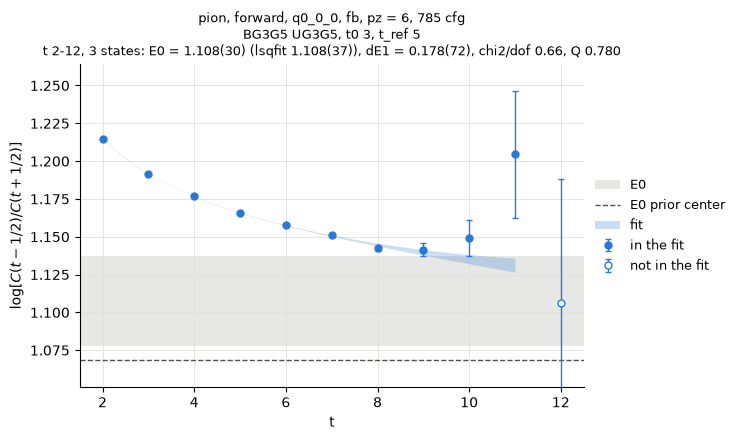

nothing is saved yet: run section 2b to save this fit


In [7]:
#======== 2pt fit: every fit parameter is here;  it prints the result and shows the effective-mass plots, it saves nothing ========
q_average_or_not = True             #True = fit the average of the four q;  False = see single_q_data;  forward ignores this
single_q_data = "pair"              #only when q_average_or_not = False:  "pair" = average of q and -q,  "one" = q only;  q comes from section 0
pt2_fit_half = "fb"                 #"forward", "backward" or "fb"
#the fit range and the gap prior of each hadron:  "window" = pz: (first t, last t);  "dE_prior" = (center, width) of every gap at every pz, the fit varies log(dE), so dE stays positive
pion_pt2_fit = {"window": {0: (3, 16), 1: (3, 15), 2: (3, 14), 3: (3, 13), 4: (3, 12), 5: (2, 12), 6: (2, 12)}, "dE_prior": (0.25, 0.4)}
proton_pt2_fit = {"window": {0: (4, 14), 1: (4, 14), 2: (4, 14), 3: (4, 14), 4: (4, 12), 5: (4, 10), 6: (4, 10)}, "dE_prior": (0.5, 0.5)}
if hadron == "pion":                #the one this fit uses
    pt2_fit_choice = pion_pt2_fit
else:
    pt2_fit_choice = proton_pt2_fit
pt2_fit_window = pt2_fit_choice["window"]
pt2_dE_prior = pt2_fit_choice["dE_prior"]
n_state = 3                         #number of states in the model
pt2_E0_center = "lattice"           #center of the E0 prior:  "lattice": cosh E = cosh m + sum(1 - cos p_i);  "continuum": E^2 = m^2 + sum(p_i^2);  p_i = 2 pi n_i / Ls
pt2_m_rest = {"pion": 0.1412, "proton": 0.4989}     #rest mass of each hadron in lattice units, you set it;  the center of the E0 prior comes from it
pt2_E0_width = 0.2                  #width of the E0 prior, the same at every pz
pt2_c_prior = (0.0, 1e4)            #(center, width) of every c_n
pt2_backward_wave = True            #True = keep the term e^{-E (Lt - t)} in the model
pt2_correlated = True               #True = full covariance;  False = only its diagonal
pt2_svdcut = 1e-7
pt2_maxit = 20000
pt2_tol = 1e-8                      #stopping tolerance of the fit
pt2_fitter = "scipy_least_squares"  #the minimizer
#the plots
meff_plot_t = np.arange(2, 19)      #the t of log[C(t) / C(t + 1)]
meff_plot_err_max = 0.1             #leave out points with a larger error, so noisy t do not set the y range
meff_color = "#2a78d6"
meff_shift = 0

#---- check the settings
print("GEVP choice", gevp_tag)
assert pt2_fit_half in ["forward", "backward", "fb"], f"pt2_fit_half = {pt2_fit_half}: use forward, backward or fb"
assert single_q_data in ["pair", "one"], f"single_q_data = {single_q_data}: use pair or one"
assert pt2_E0_center in ["lattice", "continuum"], f"pt2_E0_center = {pt2_E0_center}: use lattice or continuum"
assert n_state >= 1, f"n_state = {n_state}: use at least 1"
assert hadron in pt2_m_rest, f"no mass for {hadron} in pt2_m_rest"
assert os.path.exists(gevp_file), f"no GEVP file for {gevp_tag}: run section 1 first"

#---- read the reconstructed 2pt of this basis
C2_saved = {}
with h5py.File(gevp_file, "r") as f:
    C2_saved["forward"] = f["C2_forward"][()].real      #(cfg, q, pz, tsep)
    C2_saved["backward"] = f["C2_backward"][()].real    #(cfg, q, pz, tsep)
    pf_saved = f["pf_list"][()]                         #(q, pz, 3)
    pz_list = f["pz_list"][()]
    cfg_list = f["cfg_list"][()]
for pz in pz_list:
    assert pz in pt2_fit_window, f"pz = {pz} is missing from pt2_fit_window"

#If it's forward, we have only one type of 2pt, so just fit that one
#If it's off-forward, we could fit for example the average of (1,0,pz) and (-1,0,pz) or the average of all four since they should be the same
iq = q_list.index(q)
iq_minus = q_list.index((-q[0], -q[1], -q[2]))
if frame == "forward":
    iq_use = [0]
    pt2_q_tag = "q0_0_0"
    pt2_subfolder = "forward"
elif q_average_or_not:
    iq_use = [0, 1, 2, 3]
    pt2_q_tag = "averaged_over_q"
    pt2_subfolder = "sym_averaged_over_q"
elif single_q_data == "pair":
    iq_use = [iq, iq_minus]
    pt2_q_tag = f"q{q[0]}_{q[1]}_{q[2]}"
    pt2_subfolder = f"sym_{pt2_q_tag}"
else:
    iq_use = [iq]
    pt2_q_tag = f"q{q[0]}_{q[1]}_{q[2]}_one"
    pt2_subfolder = f"sym_{pt2_q_tag}"

#---- the data of the fit: average over the halves and the q of each cfg, then jackknife
if pt2_fit_half == "fb":
    C2_half = 0.5 * (C2_saved["forward"] + C2_saved["backward"])        #(cfg, q, pz, tsep)
else:
    C2_half = C2_saved[pt2_fit_half]                                    #(cfg, q, pz, tsep)

#Use fancy indexing to average over q's
pt2_fit_jk = jackknife(C2_half[:, iq_use].mean(axis=1))                 #(jk, pz, tsep)

#calculate central of prior based on lattice/continuous dispersion relation
m_rest = pt2_m_rest[hadron]
p_i = 2 * np.pi * pf_saved[iq_use[0]] / Ls                              #(pz, 3)
if pt2_E0_center == "lattice":
    E0_center = np.arccosh(np.cosh(m_rest) + (1 - np.cos(p_i)).sum(axis=1))     #(pz,)
else:
    E0_center = np.sqrt(m_rest ** 2 + (p_i ** 2).sum(axis=1))                   #(pz,)

#model and prior
def pt2_model(t, p):
    #sum over the states of c_n (e^{-E_n t} + e^{-E_n (Lt - t)}),  E_n = E0 + dE_1 + ... + dE_n
    E = p["E0"]
    corr = 0
    for n in range(n_state):
        if n > 0:
            E = E + p["dE"][n - 1]
        if pt2_backward_wave:
            wave = gv.exp(-E * t) + gv.exp(-E * (Lt - t))
        else:
            wave = gv.exp(-E * t)
        corr = corr + p["c"][n] * wave
    return corr


def pt2_prior(ipz):
    #returns the prior dictionary of ipz
    #calculate E0 center from dispersion relation
    #width directly set at the beginning
    prior = gv.BufferDict()
    prior["E0"] = gv.gvar(E0_center[ipz], pt2_E0_width)
    c_center = []
    c_width = []
    for n in range(n_state):
        c_center.append(pt2_c_prior[0])
        c_width.append(pt2_c_prior[1])
    prior["c"] = gv.gvar(c_center, c_width)     #(n_state,)
    if n_state > 1:
        prior["log(dE)"] = gv.log(gv.gvar(np.full(n_state - 1, float(pt2_dE_prior[0])), np.full(n_state - 1, float(pt2_dE_prior[1]))))
    return prior


#fit central value first and use the central fit's result as the starting point of jackknife fit.
n_jk = pt2_fit_jk.shape[0]
n_pz = len(pz_list)
pt2_E_jk = np.zeros((n_jk, n_pz, n_state))          #(jk, pz, state): E_n
pt2_c_jk = np.zeros((n_jk, n_pz, n_state))          #(jk, pz, state): c_n
pt2_E_central = np.zeros((n_pz, n_state))           #(pz, state): the fit of the jackknife mean
pt2_E_lsqfit_err = np.zeros((n_pz, n_state))        #(pz, state): its lsqfit error, which sees the priors
pt2_c_central = np.zeros((n_pz, n_state))           #(pz, state)
pt2_c_lsqfit_err = np.zeros((n_pz, n_state))        #(pz, state)
pt2_chi2dof = np.zeros(n_pz)                        #(pz,): the fit of the jackknife mean
pt2_Q = np.zeros(n_pz)                              #(pz,)
pt2_fit_result = {}
pt2_n_not_converged = 0                             #how many fits stopped at pt2_maxit before converging;  lsqfit gives no warning for this
gv.switch_gvar()        #stops memory from growing forever
for ipz, pz in enumerate(pz_list):
    first, last = pt2_fit_window[pz]
    t = np.arange(first, last + 1)                  #(n_t,)
    assert len(t) > n_state + 1, f"pz = {pz}: {len(t)} points for {n_state + 1} free parameters, make the window longer"
    y_jk = pt2_fit_jk[:, ipz, t]                    #(jk, n_t)

    #bias gives a factor of 1/Njk so multiply by (nik-1) to match formula
    cov = (n_jk - 1) * np.cov(y_jk, rowvar=False, bias=True)    #(n_t, n_t): jackknife covariance

    if not pt2_correlated:
        #if uncorrelated, trim the covariance matrix to diagonal
        cov = np.diag(np.diag(cov))

    fit = lsqfit.nonlinear_fit(data=(t, gv.gvar(y_jk.mean(axis=0), cov)), fcn=pt2_model, prior=pt2_prior(ipz), svdcut=pt2_svdcut, maxit=pt2_maxit, tol=pt2_tol, fitter=pt2_fitter)
    pt2_fit_result[pz] = fit
    if fit.stopping_criterion == 0:
        pt2_n_not_converged = pt2_n_not_converged + 1
    E_n = fit.p["E0"]
    for n in range(n_state):
        if n > 0:
            E_n = E_n + fit.p["dE"][n - 1]
        pt2_E_central[ipz, n] = E_n.mean
        pt2_E_lsqfit_err[ipz, n] = E_n.sdev
        pt2_c_central[ipz, n] = fit.p["c"][n].mean
        pt2_c_lsqfit_err[ipz, n] = fit.p["c"][n].sdev
    print(f"---- pz = {pz}, {' '.join(gevp_choice[pz]['basis'])}: the fit of the jackknife mean")
    print(fit)
    pt2_chi2dof[ipz] = fit.chi2 / fit.dof
    pt2_Q[ipz] = fit.Q

    for i in range(n_jk):
        fit_i = lsqfit.nonlinear_fit(data=(t, gv.gvar(y_jk[i], cov)), fcn=pt2_model, prior=pt2_prior(ipz), p0=fit.pmean, svdcut=pt2_svdcut, maxit=pt2_maxit, tol=pt2_tol, fitter=pt2_fitter)
        if fit_i.stopping_criterion == 0:
            pt2_n_not_converged = pt2_n_not_converged + 1
        E_i = fit_i.pmean["E0"]
        for n in range(n_state):
            if n > 0:
                #here, even though we used log(dE) in the prior, gvar knows dE, log() is overloaded in gvar, it knows this function
                E_i = E_i + fit_i.pmean["dE"][n - 1]
            pt2_E_jk[i, ipz, n] = E_i
            pt2_c_jk[i, ipz, n] = fit_i.pmean["c"][n]
gv.restore_gvar()

#---- print the result: jk = jackknife mean and error, lsqfit = the fit of the mean, its error sees the priors
print(f"{hadron_tag}, {frame}, {pt2_q_tag}, {pt2_fit_half}, {n_state} states, rest mass {m_rest:.4f}, {n_jk} cfg")
print(f"{'pz':>3s} {'t':>5s} {'E0 jk':>11s} {'E0 lsqfit':>11s} {'center':>8s} {'dE1 jk':>10s} {'dE1 lsqfit':>11s} {'c1/c0 jk':>10s} {'chi2/dof':>9s} {'Q':>6s}")
for ipz, pz in enumerate(pz_list):
    first, last = pt2_fit_window[pz]
    mean, err = jk(pt2_E_jk[:, ipz, 0])
    E0_text = str(gv.gvar(mean, err))
    E0_lsqfit_text = str(gv.gvar(pt2_E_central[ipz, 0], pt2_E_lsqfit_err[ipz, 0]))
    if n_state > 1:
        mean, err = jk(pt2_E_jk[:, ipz, 1] - pt2_E_jk[:, ipz, 0])
        dE1_text = str(gv.gvar(mean, err))
        dE1_lsqfit_text = str(pt2_fit_result[pz].p["dE"][0])
        mean, err = jk(pt2_c_jk[:, ipz, 1] / pt2_c_jk[:, ipz, 0])
        c_ratio_text = str(gv.gvar(mean, err))
    else:
        dE1_text = "-"
        dE1_lsqfit_text = "-"
        c_ratio_text = "-"
    print(f"{pz:3d} {first:2d}-{last:2d} {E0_text:>11s} {E0_lsqfit_text:>11s} {E0_center[ipz]:8.4f} {dE1_text:>10s} {dE1_lsqfit_text:>11s} {c_ratio_text:>10s} {pt2_chi2dof[ipz]:9.2f} {pt2_Q[ipz]:6.3f}")
print(f"fits that stopped at pt2_maxit before converging: {pt2_n_not_converged} of {n_pz * (n_jk + 1)}")

#---- the effective-mass plots, one figure per pz, shown here;  section 2b saves them together with the fit
#points: log[C(t) / C(t + 1)], filled inside the fit window, open outside;  blue band: the same of the fit curve of every jackknife sample
#gray band: E0;  dashed line: the center of the E0 prior
if pt2_backward_wave:
    backward_term = 1
else:
    backward_term = 0
meff_fig = {}       #meff_fig[pz]: the figure of this pz, kept for section 2b
for ipz, pz in enumerate(pz_list):
    first, last = pt2_fit_window[pz]
    C_jk = pt2_fit_jk[:, ipz]                           #(jk, tsep)
    with np.errstate(invalid="ignore"):                 #a negative C at a noisy t gives NaN, those points are dropped below
        m, e = jk(np.log(C_jk[:, meff_plot_t] / C_jk[:, meff_plot_t + 1]))
    m = np.where(e < meff_plot_err_max, m, np.nan)
    in_fit = (meff_plot_t >= first) & (meff_plot_t < last)      #both C(t) and C(t + 1) are in the fit

    #the band: the model at t and t + 1 for every jackknife sample
    t_band = np.linspace(first, last - 1, 60)           #(n_t,)
    E_n = pt2_E_jk[:, ipz, :, None]                     #(jk, state, 1)
    c_n = pt2_c_jk[:, ipz, :, None]                     #(jk, state, 1)
    C_t = (c_n * (np.exp(-E_n * t_band) + backward_term * np.exp(-E_n * (Lt - t_band)))).sum(axis=1)                   #(jk, n_t)
    C_t1 = (c_n * (np.exp(-E_n * (t_band + 1)) + backward_term * np.exp(-E_n * (Lt - t_band - 1)))).sum(axis=1)        #(jk, n_t)
    band_mean, band_err = jk(np.log(C_t / C_t1))

    mean, err = jk(pt2_E_jk[:, ipz, 0])
    E0 = gv.gvar(mean, err)
    E0_lsqfit = gv.gvar(pt2_E_central[ipz, 0], pt2_E_lsqfit_err[ipz, 0])
    if n_state > 1:
        mean, err = jk(pt2_E_jk[:, ipz, 1] - pt2_E_jk[:, ipz, 0])
        dE1_text = f"dE1 = {gv.gvar(mean, err)}, "
    else:
        dE1_text = ""

    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.axhspan(E0.mean - E0.sdev, E0.mean + E0.sdev, color="#e7e7e5", lw=0, zorder=0, label="E0")
    ax.axhline(E0_center[ipz], color="#52514e", lw=1, ls="--", zorder=1, label="E0 prior center")
    ax.fill_between(t_band + meff_shift, band_mean - band_err, band_mean + band_err, color=meff_color, alpha=0.25, lw=0, zorder=1, label="fit")
    ax.errorbar(meff_plot_t[in_fit] + meff_shift, m[in_fit], e[in_fit], color=meff_color, marker="o", ms=5, ls="none", elinewidth=1, capsize=2, zorder=2, label="in the fit")
    ax.errorbar(meff_plot_t[~in_fit] + meff_shift, m[~in_fit], e[~in_fit], color=meff_color, marker="o", mfc="white", ms=5, ls="none", elinewidth=1, capsize=2, zorder=2, label="not in the fit")

    #y range from the points in the fit, so the small t do not squash the plateau
    y_low = np.nanmin(np.append(m[in_fit] - e[in_fit], [E0.mean - E0.sdev, E0_center[ipz]]))
    y_high = np.nanmax(np.append(m[in_fit] + e[in_fit], [E0.mean + E0.sdev, E0_center[ipz]]))
    ax.set_ylim(y_low - 0.1 * (y_high - y_low), y_high + 0.1 * (y_high - y_low))
    ax.grid(color="#e1e0d9", lw=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel("t")
    ax.set_ylabel(r"$\log[C(t - 1/2) / C(t + 1/2)]$")
    ax.set_title(f"{hadron_tag}, {frame}, {pt2_q_tag}, {pt2_fit_half}, pz = {pz}, {n_jk} cfg\n"
                 f"{' '.join(gevp_choice[pz]['basis'])}, t0 {gevp_choice[pz]['t0']}, t_ref {gevp_choice[pz]['t_ref']}\n"
                 f"t {first}-{last}, {n_state} states: E0 = {E0} (lsqfit {E0_lsqfit}), {dE1_text}chi2/dof {pt2_chi2dof[ipz]:.2f}, Q {pt2_Q[ipz]:.3f}", fontsize=9)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=9)
    fig.tight_layout()
    meff_fig[pz] = fig
    plt.show()
print("nothing is saved yet: run section 2b to save this fit")

## 2b. Save the 2pt fit?

In [8]:
#======== save the 2pt fit of section 2a?  it asks, and saves only if you answer y ========
#one file for this fit, replaced when you save again;  the file states the fitted data and every setting
answer = input("save this 2pt fit? [y/N] ")
if answer.strip().lower() in ("y", "yes"):
    pt2_range_tag = "_".join(f"{pt2_fit_window[pz][0]}-{pt2_fit_window[pz][1]}n{n_state}" for pz in pz_list)     #first t - last t, number of states, one per pz
    pt2_fit_file = pt2_fit_path(frame, pt2_q_tag, pt2_subfolder, pt2_fit_half)
    if os.path.exists(pt2_fit_file):
        print("replacing", pt2_fit_file)
    os.makedirs(os.path.dirname(pt2_fit_file), exist_ok=True)
    with h5py.File(pt2_fit_file, "w") as f:
        #results
        f["fit_data_jk"] = pt2_fit_jk                           #(jk, pz, tsep): the data, for the plots
        f["E_jk"] = pt2_E_jk                                    #(jk, pz, state)
        f["c_jk"] = pt2_c_jk                                    #(jk, pz, state)
        f["E_central"] = pt2_E_central                          #(pz, state)
        f["E_lsqfit_err"] = pt2_E_lsqfit_err                    #(pz, state)
        f["c_central"] = pt2_c_central                          #(pz, state)
        f["c_lsqfit_err"] = pt2_c_lsqfit_err                    #(pz, state)
        f["chi2dof"] = pt2_chi2dof                              #(pz,)
        f["Q"] = pt2_Q                                          #(pz,)
        f["n_not_converged"] = pt2_n_not_converged
        #settings
        f["q_average_or_not"] = q_average_or_not
        f["single_q_data"] = single_q_data
        f["q_tag"] = pt2_q_tag
        f["subfolder"] = pt2_subfolder
        f["q_list"] = [q_list[i] for i in iq_use]               #(n_q, 3): the q that went in
        f["fit_half"] = pt2_fit_half
        f["fit_window"] = [pt2_fit_window[pz] for pz in pz_list]    #(pz, 2): first t, last t
        f["fit_range_tag"] = pt2_range_tag
        f["n_state"] = n_state
        f["E0_center_kind"] = pt2_E0_center
        f["E0_prior_center"] = E0_center                        #(pz,)
        f["E0_prior_width"] = pt2_E0_width
        f["m_rest"] = m_rest
        f["dE_prior"] = pt2_dE_prior                            #(center, width)
        f["c_prior"] = pt2_c_prior                              #(center, width)
        f["backward_wave"] = pt2_backward_wave
        f["correlated"] = pt2_correlated
        f["svdcut"] = pt2_svdcut
        f["maxit"] = pt2_maxit
        f["tol"] = pt2_tol
        f["fitter"] = pt2_fitter
        #what the data are
        f["frame"] = frame
        f["hadron_tag"] = hadron_tag
        f["ncfg"] = ncfg
        f["cfg_list"] = cfg_list
        f["pz_list"] = pz_list
        f["pf_list"] = pf_saved[iq_use[0]]                      #(pz, 3)
        f["Ls"] = Ls
        f["Lt"] = Lt
        save_gevp_info(f, op_basis)
    print("saved", pt2_fit_file)

    #the effective-mass plots of section 2a, in meff_plots/{forward, sym_q..., sym_averaged_over_q}
    meff_plot_dir = os.path.join(save_dir, "meff_plots", pt2_subfolder)
    os.makedirs(meff_plot_dir, exist_ok=True)
    for pz in pz_list:
        meff_fig[pz].savefig(os.path.join(meff_plot_dir, f"meff_{frame}_{pt2_q_tag}_{gevp_tag}_{pt2_fit_half}_ncfg{ncfg}_{hadron_tag}_pz{pz}.png"), dpi=150)
    print("saved", len(pz_list), "plots in", meff_plot_dir)
else:
    print("not saved")

save this 2pt fit? [y/N]  y


saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/AI_assisted_matrix_element_analysis/pion_default/2pt_fit_data/forward/2pt_fit_forward_q0_0_0_pion_default_fb_ncfg785_pion.h5
saved 7 plots in /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/AI_assisted_matrix_element_analysis/pion_default/meff_plots/forward


## 3. 3pt, with the reconstructed 2pt

In [9]:
#======== 3pt, method 1: one file per q ========
pt3_q_list = q_list         #the q to make;  q_list = all of them, or for example [(2,0,0)]
tau_list = np.arange(20)
half_sign = {"forward": +1, "backward": -1}     #operator at t_src + tau (forward), t_src - tau (backward)

print("GEVP choice", gevp_tag)
assert phase_attached_to in ["FF", "2pt"], f"phase_attached_to = {phase_attached_to}: use FF or 2pt"
assert os.path.exists(gevp_file), f"no GEVP file for {gevp_tag}: run section 1 first"

#---- the saved 2pt and v0 of this basis
C2_saved = {}
v0_saved = {}
with h5py.File(gevp_file, "r") as f:
    for half in half_sign:
        C2_saved[half] = f[f"C2_{half}"][()]    #(cfg, q, pz, tsep)
        v0_saved[half] = f[f"v0_{half}"][()]    #(q, pz, op)

for q_i in pt3_q_list:
    print("3pt at q =", q_i)
    iq = q_list.index(q_i)
    iq_minus = q_list.index((-q_i[0], -q_i[1], -q_i[2]))

    #---- source positions, and C3input = v^dagger C v with the saved v0
    cfg_list = read_joined(q_i, "C3input", "cfg_list")          #(cfg,): the cfgs of all data sets
    pz_list = read_shared(q_i, "C3input", "pz_list")
    t_src_list = read_joined(q_i, "C3input", "t_src_list")      #(cfg, t_src): the slice of each t_src index, not sorted, shifts per cfg
    x_src = read_joined(q_i, "C3input", "x_src_list")           #(cfg, 4): source positions, they shift per cfg
    y_src = read_joined(q_i, "C3input", "y_src_list")           #(cfg, 4)
    z_src = read_joined(q_i, "C3input", "z_src_list")           #(cfg, 8)
    raw_forward, raw_backward = read_pt2(q_i, "C3input")
    C3input = {}                                #C3input[half]: (cfg, t_src, pz, tsep), c_sign already in
    C3input["forward"] = apply_v0(op_matrix(raw_forward, op_basis), v0_saved["forward"][iq])
    C3input["backward"] = apply_v0(op_matrix(raw_backward, op_basis), v0_saved["backward"][iq])

    #mean of exp(-i 2pi/Ls q.x_src) over the 128 source positions, one number per cfg: 1 at q = 0, ~1e-16 at the four sym q
    phase_mean = (np.exp(-2j * np.pi * q_i[0] * x_src / Ls).mean(axis=1)
                  * np.exp(-2j * np.pi * q_i[1] * y_src / Ls).mean(axis=1)
                  * np.exp(-2j * np.pi * q_i[2] * z_src / Ls).mean(axis=1))

    #---- the gluon operator: FF (cfg, munu, rhosig, hyp, w, t), munu order XY, YZ, XZ, XT, YT, ZT
    #every data set has its own FF file;  the cfgs of its 2pt file are looked up in it by their cfg number, then the data sets are joined in the same order as the 2pt
    O_parts = []
    for data in data_sets:
        with h5py.File(pt2_file(data, q_i, "C3input"), "r") as f:
            cfg_of_set = f["cfg_list"][()]              #the 2pt cfgs of this data set, its own numbers without cfg_shift
        FF_file = os.path.join(data["dir"], ff_name.format(qx=q_i[0], qy=q_i[1], qz=q_i[2], ncfg=data["ff_ncfg"]))
        print("reading", FF_file)
        assert os.path.exists(FF_file), f"no such file: {FF_file}"
        with h5py.File(FF_file, "r") as f:
            assert tuple(f["q"][()]) == q_i
            FF_cfg = f["cfg_list"][()]
            assert np.isin(cfg_of_set, FF_cfg).all(), f"{data['name']}: some 2pt cfgs are not in the FF file"
            idx = np.searchsorted(FF_cfg, cfg_of_set)   #the 2pt cfgs are not the first FF cfgs
            assert np.array_equal(FF_cfg[idx], cfg_of_set)
            ihyp = list(f["hyp_list"][()]).index(hyp)
            if data is data_sets[0]:
                w_list = f["w_list"][()]
            assert np.array_equal(f["w_list"][()], w_list), f"{data['name']}: other w than {data_sets[0]['name']}"
            TXTX = f["FF"][idx, 3, 3, ihyp]
            TYTY = f["FF"][idx, 4, 4, ihyp]
            XYXY = f["FF"][idx, 0, 0, ihyp]
        O_parts.append(TXTX + TYTY - 2 * XYXY)      #(cfg of this set, w, t)
    O = np.concatenate(O_parts)                     #(cfg, w, t)

    #---- connected minus vacuum, for every jackknife sample
    n_cfg, n_tsrc = t_src_list.shape
    i_cfg = np.arange(n_cfg)[:, None, None]
    pt3_jk = {}
    C2pf_jk = {}
    C2pi_jk = {}
    for half in half_sign:
        C2pf_cfg = C2_saved[half][:, iq]            #(cfg, pz, tsep): plain 2pt at p_f = q/2
        C2pi_cfg = C2_saved[half][:, iq_minus]      #(cfg, pz, tsep): plain 2pt at p_i = -q/2, C2pi(q) = C2pf(-q)
        t_op = (t_src_list[:, :, None] + half_sign[half] * tau_list) % Lt       #(cfg, t_src, tau)
        O_tau = O[i_cfg, :, t_op]                   #(cfg, t_src, tau, w): numpy puts w last here
        connected = np.einsum("cspT,cstw->cwpTt", C3input[half], O_tau, optimize=True) / n_tsrc     #(cfg, w, pz, tsep, tau)
        if phase_attached_to == "FF":
            pt2_avg = C2pf_cfg                      #(cfg, pz, tsep), plain, no source phase
            op_avg = O_tau.mean(axis=1) * phase_mean[:, None, None]     #(cfg, tau, w), the source phase is here
        else:
            pt2_avg = C3input[half].mean(axis=1)    #(cfg, pz, tsep), the source phase is here
            op_avg = O_tau.mean(axis=1)             #(cfg, tau, w), no source phase
        pt3_jk[half] = jackknife(connected) - np.einsum("cpT,ctw->cwpTt", jackknife(pt2_avg), jackknife(op_avg), optimize=True)    #(jk, w, pz, tsep, tau)
        C2pf_jk[half] = jackknife(C2pf_cfg).real    #(jk, pz, tsep)
        C2pi_jk[half] = jackknife(C2pi_cfg).real    #(jk, pz, tsep)

    #check: C3/C2 at tsep 8, tau 4, w 0
    for half in half_sign:
        m, e = jk(pt3_jk[half][:, 0, :, 8, 4].real / C2pf_jk[half][:, :, 8])
        print(half, " ".join(f"{a:+.3f}({b * 1e3:.0f})" for a, b in zip(m, e)))

    #---- save the 3pt, with the jackknife 2pt that goes with it
    os.makedirs(os.path.dirname(pt3_path(q_i)), exist_ok=True)
    with h5py.File(pt3_path(q_i), "w") as f:
        for half in half_sign:
            f[f"pt3_{half}"] = pt3_jk[half]         #(jk, w, pz, tsep, tau), complex
            f[f"C2pf_{half}"] = C2pf_jk[half]       #(jk, pz, tsep)
            f[f"C2pi_{half}"] = C2pi_jk[half]       #(jk, pz, tsep)
        f["q"] = q_i
        f["cfg_list"] = cfg_list
        f["pz_list"] = pz_list
        f["w_list"] = w_list
        f["tsep_list"] = np.arange(pt3_jk["forward"].shape[3])
        f["tau_list"] = tau_list
        f["hyp"] = hyp
        save_gevp_info(f, op_basis)
        f["phase_attached_to"] = phase_attached_to
    print("saved", pt3_path(q_i))

GEVP choice pion_default
3pt at q = (0, 0, 0)
reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_forward_q0_0_0_C3input_fb_tsep20_3072src_ncfg585_pion.h5
reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_frontier_streamd/2pt_coulomb_rho4p5z2p25-rho1p5_frac0p8-0_smear_GEVP_forward_q0_0_0_C3input_fb_tsep20_3072src_ncfg200_pion.h5
reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/FF_hyp0-8_w0-9_q0_0_0_ncfg800.h5
reading /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_frontier_streamd/FF_hyp0-8_w0-9_q0_0_0_ncfg798.h5
forward -0.128(15) -0.212(11) -0.353(17) -0.252(6) -0.252(7) -0.310(20) -0.232(17)
backward -0.142(15) -0.213(11) -0.337(16) -0.253(6) -0.242(8) -0.310(20) -0.234(17)
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/AI_assisted_matrix_element_a

## 4. Ratio and ratio plots

In [10]:
#======== ratio, and its plots: one figure per w and pz ========
#R(tsep, tau) = C3(tsep, tau) / C2pf(tsep) * sqrt[ C2pi(tsep - tau) C2pf(tau) C2pf(tsep) / (C2pf(tsep - tau) C2pi(tau) C2pi(tsep)) ]
#the ground state gives M / (2 sqrt(E_f E_i)) at every tsep, tau;  at q = 0 the square root is 1
ratio_q_average = True                      #sym only: True = average the 3pt and 2pt over the four q, then make the ratio;  False = the q of section 0
plot_half = "fb"                            #"forward", "backward" or "fb"
plot_tsep_list = [4,5,6,7,8,9,10,11,12,13,14,15]        #up to 8 values
plot_tau_skip = 1                           #leave out tau < plot_tau_skip and tau > tsep - plot_tau_skip
plot_err_max = 0.3                          #leave out points with a larger error, so noisy tsep do not set the y range

print("GEVP choice", gevp_tag)
half_list = ["forward", "backward"]

#---- which q go in, and the label of this ratio
if frame == "forward":
    ratio_q_list = [(0,0,0)]
    ratio_q_tag = "q0_0_0"
    ratio_subfolder = "forward"
elif ratio_q_average:
    ratio_q_list = q_list
    ratio_q_tag = "averaged_over_q"
    ratio_subfolder = "sym_averaged_over_q"
else:
    ratio_q_list = [q]
    ratio_q_tag = f"q{q[0]}_{q[1]}_{q[2]}"
    ratio_subfolder = f"sym_{ratio_q_tag}"

#---- read the 3pt files and average over q
pt3_use = {"forward": 0, "backward": 0}     #pt3_use[half]: (jk, w, pz, tsep, tau)
c2f_jk = {"forward": 0, "backward": 0}      #c2f_jk[half]: (jk, pz, tsep)
c2i_jk = {"forward": 0, "backward": 0}      #c2i_jk[half]: (jk, pz, tsep)
for q_i in ratio_q_list:
    assert os.path.exists(pt3_path(q_i)), f"no 3pt file at q = {q_i} for {gevp_tag}: run section 3 first"
    with h5py.File(pt3_path(q_i), "r") as f:
        if q_i == ratio_q_list[0]:
            cfg_list = f["cfg_list"][()]
            pz_list = f["pz_list"][()]
            w_list = f["w_list"][()]
            tsep_list = f["tsep_list"][()]
            tau_list = f["tau_list"][()]
        assert np.array_equal(f["cfg_list"][()], cfg_list), f"q = {q_i}: other cfgs, the jackknife samples would not match"
        for half in half_list:
            pt3_use[half] = pt3_use[half] + f[f"pt3_{half}"][()] / len(ratio_q_list)
            c2f_jk[half] = c2f_jk[half] + f[f"C2pf_{half}"][()] / len(ratio_q_list)
            c2i_jk[half] = c2i_jk[half] + f[f"C2pi_{half}"][()] / len(ratio_q_list)

#---- the ratio
tsep_grid, tau_grid = np.meshgrid(tsep_list, tau_list, indexing="ij")           #(tsep, tau)
in_window = tau_grid <= tsep_grid
rest_grid = np.where(in_window, tsep_grid - tau_grid, 0)                        #tsep - tau, the 0 is only used where R is set to NaN


def build_ratio(pt3, c2f, c2i):
    #pt3 (jk, w, pz, tsep, tau), c2f and c2i real (jk, pz, tsep) -> R (jk, w, pz, tsep, tau), complex, NaN for tau > tsep
    root = np.sqrt(c2i[:, :, rest_grid] * c2f[:, :, tau_grid] * c2f[:, :, tsep_grid]
                   / (c2f[:, :, rest_grid] * c2i[:, :, tau_grid] * c2i[:, :, tsep_grid]))    #(jk, pz, tsep, tau)
    return np.where(in_window, pt3 * (root / c2f[:, :, tsep_grid])[:, None], np.nan)


ratio_jk = {}
for half in half_list:
    ratio_jk[half] = build_ratio(pt3_use[half], c2f_jk[half], c2i_jk[half])
#forward and backward together: average the jackknife 3pt and 2pt first, then the ratio
ratio_jk["fb"] = build_ratio(0.5 * (pt3_use["forward"] + pt3_use["backward"]),
                             0.5 * (c2f_jk["forward"] + c2f_jk["backward"]),
                             0.5 * (c2i_jk["forward"] + c2i_jk["backward"]))

#check: Re R at tsep 8, tau 4, w 0
for half in ratio_jk:
    m, e = jk(ratio_jk[half][:, 0, :, 8, 4].real)
    print(f"{half:8s}", " ".join(f"{a:+.3f}({b * 1e3:.0f})" for a, b in zip(m, e)))

#---- save the ratio
ratio_file = os.path.join(save_dir, "ratio_data", ratio_subfolder, f"ratio_{frame}_{ratio_q_tag}_{gevp_tag}_phase{phase_attached_to}_hyp{hyp}_ncfg{ncfg}_{hadron_tag}.h5")
os.makedirs(os.path.dirname(ratio_file), exist_ok=True)
with h5py.File(ratio_file, "w") as f:
    for half in ratio_jk:
        f[f"ratio_{half}"] = ratio_jk[half]         #(jk, w, pz, tsep, tau), complex, NaN for tau > tsep;  half = forward, backward, fb
    f["q_list"] = ratio_q_list                      #(n_q, 3): the q that went in
    f["q_tag"] = ratio_q_tag
    f["subfolder"] = ratio_subfolder
    f["frame"] = frame
    f["hadron_tag"] = hadron_tag
    f["ncfg"] = ncfg
    f["cfg_list"] = cfg_list
    f["pz_list"] = pz_list
    f["w_list"] = w_list
    f["tsep_list"] = tsep_list
    f["tau_list"] = tau_list
    f["hyp"] = hyp
    save_gevp_info(f, op_basis)
    f["phase_attached_to"] = phase_attached_to
print("saved", ratio_file)

#---- plot: saved in ratio_plots/{forward, sym_q..., sym_averaged_over_q}/pz{pz}
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948", "#8c564b", "#17becf",
          "#7f7f7f", "#bcbd22", "#000000", "#c49c94", "#9edae5", "#ff9896", "#98df8a", "#c5b0d5", "#ffbb78", "#aec7e8"]
markers = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "p", "h", "H", "d", "8", "1", "2", "3", "4", "+"]
ratio_plot_dir = os.path.join(save_dir, "ratio_plots", ratio_subfolder)
for iw, w in enumerate(w_list):
    for ipz, pz in enumerate(pz_list):
        pz_dir = os.path.join(ratio_plot_dir, f"pz{pz}")
        os.makedirs(pz_dir, exist_ok=True)
        fig, ax = plt.subplots(figsize=(7.5, 4.5))
        for i, tsep in enumerate(plot_tsep_list):
            tau = np.arange(plot_tau_skip, tsep - plot_tau_skip + 1)
            m, e = jk(ratio_jk[plot_half][:, iw, ipz, tsep, tau].real)
            m = np.where(e < plot_err_max, m, np.nan)                           #NaN leaves a gap in the line instead of joining across the dropped points
            x = tau - tsep / 2 + 0.5 / len(plot_tsep_list) * (i - (len(plot_tsep_list) - 1) / 2)     #small shift so the error bars do not sit on top of each other   #small shift so the error bars do not sit on top of each other
            ax.errorbar(x, m, e, color=colors[i], marker=markers[i], ms=5, lw=0.8, elinewidth=1, capsize=2, label=f"tsep = {tsep}")
        ax.axhline(0, color="#898781", lw=0.8)
        ax.grid(color="#e1e0d9", lw=0.6)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_xlabel(r"$\tau - t_{\rm sep}/2$")
        ax.set_ylabel("Re R")
        ax.set_title(f"{hadron_tag}, {frame}, {ratio_q_tag}, {plot_half}, phase on {phase_attached_to}, hyp {hyp}, w = {w}, pz = {pz}, {ncfg} cfg", fontsize=10)
        ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=9)
        fig.tight_layout()
        fig.savefig(os.path.join(pz_dir, f"ratio_{frame}_{ratio_q_tag}_{gevp_tag}_phase{phase_attached_to}_{hadron_tag}_{plot_half}_hyp{hyp}_w{w}_pz{pz}.png"), dpi=150)
        plt.close(fig)
print("saved", len(w_list) * len(pz_list), "plots in", ratio_plot_dir)

GEVP choice pion_default
forward  -0.128(15) -0.212(11) -0.353(17) -0.252(6) -0.252(7) -0.310(20) -0.232(17)
backward -0.142(15) -0.213(11) -0.337(16) -0.253(6) -0.242(8) -0.310(20) -0.234(17)
fb       -0.135(14) -0.212(10) -0.345(16) -0.252(5) -0.247(7) -0.310(19) -0.233(17)
saved /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/AI_assisted_matrix_element_analysis/pion_default/ratio_data/forward/ratio_forward_q0_0_0_pion_default_phase2pt_hyp8_ncfg785_pion.h5
saved 70 plots in /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/AI_assisted_matrix_element_analysis/pion_default/ratio_plots/forward


## 5. Ratio fit: parameters of each pz, fold switch, shared-fraction switch

In [ ]:
#======== ratio fit: every fit parameter is here, each pz has its own;  this cell saves nothing: section 6a shows the fit, section 6b asks whether to save it ========
#the model of one pz, its w fitted together:
#  shared_fraction False:  R_w = M00_w + Ai_w (e^{-dE tau} + e^{-dE (tsep - tau)}) + Afi_w e^{-dE tsep}
#  shared_fraction True:   R_w = M00_w [1 + Ai (e^{-dE tau} + e^{-dE (tsep - tau)}) + Afi e^{-dE tsep}],  one Ai, one Afi and one dE for all w
fit_ratio_file = ratio_file         #the file section 4 just saved;  in a new kernel paste here the path that section 4 printed, as a string
fit_half = "fb"                     #"forward", "backward" or "fb"
fit_pz_run = [0, 1, 2, 3, 4, 5, 6]  #the pz to fit in this run;  to redo one pz, change its lines below and put only that pz here

#the fit parameters of each pz;  each hadron has its own set, pion_fit and proton_fit:
#  "tsep": (first tsep, last tsep) in the fit
#  "tau_skip": tau = tau_skip .. tsep - tau_skip
#  "fold": True = fit the average of R(tsep, tau) and R(tsep, tsep - tau), at tau = tau_skip .. tsep//2;  False = fit every tau
#  "shared_fraction": True or False, the two models above
#  "shared_gap": True = one gap for all w;  False = each w has its own gap (shared_fraction True needs shared_gap True)
#  "cross_w_factor": the off-w blocks of the covariance are multiplied by this:  0 = removed, 1 = the full all-w covariance
#  "svdcut"
#  "dE_prior": (center, width) of the gap;  the fit varies log(dE), so dE stays positive
#  "M00_prior": (center, width);  the center must be negative, the fit varies log(-M00), so M00 stays negative
#  "Ai_prior", "Afi_prior": (center, width);  with shared_fraction True, Ai and Afi are fractions of M00
pion_fit = {}
pion_fit[0] = {"tsep": (6, 15), "tau_skip": 3, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
               "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
pion_fit[1] = {"tsep": (5, 13), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
               "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
pion_fit[2] = {"tsep": (4, 13), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
               "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
pion_fit[3] = {"tsep": (4, 13), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
               "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
pion_fit[4] = {"tsep": (4, 12), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
               "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
pion_fit[5] = {"tsep": (4, 9), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
               "dE_prior": (0.3, 0.5), "M00_prior": (-1.0, 100.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
pion_fit[6] = {"tsep": (4, 9), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
               "dE_prior": (0.3, 0.5), "M00_prior": (-1.0, 100.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
proton_fit = {}
proton_fit[0] = {"tsep": (6, 13), "tau_skip": 3, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
                 "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
proton_fit[1] = {"tsep": (5, 13), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
                 "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
proton_fit[2] = {"tsep": (4, 13), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
                 "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
proton_fit[3] = {"tsep": (4, 13), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
                 "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
proton_fit[4] = {"tsep": (4, 12), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
                 "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
proton_fit[5] = {"tsep": (4, 9), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
                 "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
proton_fit[6] = {"tsep": (4, 9), "tau_skip": 2, "fold": True, "shared_fraction": True, "shared_gap": True, "cross_w_factor": 1.0, "svdcut": 1e-2,
                 "dE_prior": (0.5, 0.5), "M00_prior": (-1.0, 10.0), "Ai_prior": (0.0, 1e4), "Afi_prior": (0.0, 1e4)}
if hadron == "pion":                #the one this fit uses
    fit_choice = pion_fit
else:
    fit_choice = proton_fit

#the same for every pz
fit_correlated = True               #True = full covariance;  False = only its diagonal
fit_cov_per_sample = True           #True = the fit of jackknife sample j uses the covariance made without cfg j;  False = every sample uses the covariance of all cfgs
fit_maxit = 20000
fit_tol = 1e-8                      #stopping tolerance of the fit
fit_fitter = "scipy_least_squares"  #the minimizer
#fixed, not a setting: the fit of the jackknife mean starts from the centers of the priors (lsqfit's own start);  the fit of every jackknife sample starts from the fit of the mean

#---- read the ratio;  it has to be the ratio of the settings of section 0, because the saved fits are named after them
assert fit_half in ["forward", "backward", "fb"], f"fit_half = {fit_half}: use forward, backward or fb"
with h5py.File(fit_ratio_file, "r") as f:
    fit_data_jk = f[f"ratio_{fit_half}"][()]        #(jk, w, pz, tsep, tau), complex
    fit_w_list = f["w_list"][()]
    fit_pz_list = list(f["pz_list"][()])
    fit_q_tag = f["q_tag"].asstr()[()]
    fit_subfolder = f["subfolder"].asstr()[()]
    fit_basis = list(f["gevp_basis"].asstr()[()])   #(pz,): the operators of each pz in words
    assert f["gevp_tag"].asstr()[()] == gevp_tag, "the ratio file has another gevp_tag than section 0"
    assert f["frame"].asstr()[()] == frame, "the ratio file has another frame than section 0"
    assert f["hadron_tag"].asstr()[()] == hadron_tag, "the ratio file has another hadron than section 0"
    assert f["ncfg"][()] == ncfg, "the ratio file has another ncfg than section 0"
    assert f["hyp"][()] == hyp, "the ratio file has another hyp than section 0"
    assert f["phase_attached_to"].asstr()[()] == phase_attached_to, "the ratio file has another phase_attached_to than section 0"
print("ratio file", fit_ratio_file)
for pz in fit_pz_run:
    assert pz in fit_pz_list, f"pz = {pz} is not in the ratio file"
    assert pz in fit_choice, f"pz = {pz} is missing from fit_choice"
    assert 0 <= fit_choice[pz]["cross_w_factor"] <= 1, f"pz = {pz}: cross_w_factor = {fit_choice[pz]['cross_w_factor']}: use a number from 0 to 1"
    if fit_choice[pz]["shared_fraction"]:
        assert fit_choice[pz]["shared_gap"], f"pz = {pz}: shared_fraction True needs shared_gap True"


#---- the model and the prior
if not gv.BufferDict.has_distribution("neglog"):       #a name for gvar, like its own "log":  the fit varies neglog(M00), and p["M00"] = -exp(neglog(M00))
    gv.BufferDict.add_distribution("neglog", lambda x: -gv.exp(x))


def ratio_model(x, p):
    #forward and sym: p_i and p_f have the same energies and overlaps, so one gap and Af = Ai
    #x["iw"] says which w of this fit each point belongs to;  x["shared_gap"] and x["shared_fraction"] are the switches of this pz
    tsep = x["tsep"]
    tau = x["tau"]
    iw = x["iw"]
    if x["shared_gap"]:
        dE = p["dE"][0]
    else:
        dE = p["dE"][iw]
    excited_tau = gv.exp(-dE * tau) + gv.exp(-dE * (tsep - tau))
    excited_tsep = gv.exp(-dE * tsep)
    if x["shared_fraction"]:
        return p["M00"][iw] * (1 + p["Ai"][0] * excited_tau + p["Afi"][0] * excited_tsep)
    else:
        return p["M00"][iw] + p["Ai"][iw] * excited_tau + p["Afi"][iw] * excited_tsep


def ratio_prior(n_group, choice):
    #choice = fit_choice[pz];  n_group = how many w are in this fit
    #one M00 for each w;  Ai and Afi: one for each w, or one for all w with shared_fraction;  the gap: one for each w, or one for all w with shared_gap
    if choice["shared_fraction"]:
        n_amp = 1
    else:
        n_amp = n_group
    if choice["shared_gap"]:
        n_gap = 1
    else:
        n_gap = n_group
    prior = gv.BufferDict()
    prior["neglog(M00)"] = gv.log(-gv.gvar(np.full(n_group, float(choice["M00_prior"][0])), np.full(n_group, float(choice["M00_prior"][1]))))    #read it as fit.p["M00"], as with log(dE)
    prior["Ai"] = gv.gvar(np.full(n_amp, float(choice["Ai_prior"][0])), np.full(n_amp, float(choice["Ai_prior"][1])))
    prior["Afi"] = gv.gvar(np.full(n_amp, float(choice["Afi_prior"][0])), np.full(n_amp, float(choice["Afi_prior"][1])))
    prior["log(dE)"] = gv.log(gv.gvar(np.full(n_gap, float(choice["dE_prior"][0])), np.full(n_gap, float(choice["dE_prior"][1]))))    #read the gap as fit.p["dE"], fit.psdev["dE"] is not its error
    return prior


#---- one pz after the other:  first the jackknife mean, then every jackknife sample, started from the fit of the mean
n_jk = fit_data_jk.shape[0]
n_w = len(fit_w_list)
fit_param_names = ["M00", "Ai", "Afi", "dE"]
param_jk = {}               #param_jk[pz][name]: (jk, w);  a parameter that is shared by all w has the same number at every w
param_central = {}          #param_central[pz][name]: (w,), the fit of the jackknife mean
param_lsqfit_err = {}       #param_lsqfit_err[pz][name]: (w,), its lsqfit error, which sees the priors
fit_chi2 = {}               #fit_chi2[pz]: (w,), the fit of the jackknife mean;  when all w are fitted together, every w shows the chi2 of that one fit
fit_dof = {}                #fit_dof[pz]: (w,)
fit_Q = {}                  #fit_Q[pz]: (w,)
fit_svd_modes = {}          #fit_svd_modes[pz]: (w,), how many modes of the covariance were raised by the svdcut
fit_points = {}             #fit_points[pz]: the tsep and tau of every fitted point of one w
fit_y_jk = {}               #fit_y_jk[pz]: (jk, w, n_point), the fitted Re R, folded if "fold"
fit_n_not_converged = {}    #fit_n_not_converged[pz]: how many fits stopped at fit_maxit before converging;  lsqfit gives no warning for this
fit_n_total = {}            #fit_n_total[pz]: how many fits were done
check_fig = {}              #the figures of section 6a;  emptied here, so an old figure cannot be saved with a new fit
for pz in fit_pz_run:
    time_start = time.time()
    ipz = fit_pz_list.index(pz)
    choice = fit_choice[pz]
    first, last = choice["tsep"]
    tau_skip = choice["tau_skip"]

    #the points of one w
    tsep_points = []
    tau_points = []
    for tsep in range(first, last + 1):
        if choice["fold"]:
            tau_last = tsep // 2
        else:
            tau_last = tsep - tau_skip
        for tau in range(tau_skip, tau_last + 1):
            tsep_points.append(tsep)
            tau_points.append(tau)
    tsep_points = np.array(tsep_points)     #(n_point,)
    tau_points = np.array(tau_points)       #(n_point,)
    n_point = len(tsep_points)
    assert n_point > 3, f"pz = {pz}: {n_point} points for 3 free parameters, make the window larger"
    fit_points[pz] = {"tsep": tsep_points, "tau": tau_points}

    #the data: Re R at these points
    y_all = fit_data_jk[:, :, ipz, tsep_points, tau_points].real                        #(jk, w, n_point)
    if choice["fold"]:
        y_mirror = fit_data_jk[:, :, ipz, tsep_points, tsep_points - tau_points].real   #(jk, w, n_point): the same points seen from the sink, tau -> tsep - tau
        y_all = 0.5 * (y_all + y_mirror)
    assert not np.isnan(y_all).any(), f"pz = {pz}: NaN in the ratio at the fit points, lower the last tsep"
    fit_y_jk[pz] = y_all

    #which w are fitted together
    if choice["shared_gap"] or choice["cross_w_factor"] != 0:
        w_groups = [list(range(n_w))]       #all w in one fit
    else:
        w_groups = []
        for iw in range(n_w):
            w_groups.append([iw])           #each w in its own fit

    param_jk[pz] = {}
    param_central[pz] = {}
    param_lsqfit_err[pz] = {}
    for name in fit_param_names:
        param_jk[pz][name] = np.zeros((n_jk, n_w))
        param_central[pz][name] = np.zeros(n_w)
        param_lsqfit_err[pz][name] = np.zeros(n_w)
    fit_chi2[pz] = np.zeros(n_w)
    fit_dof[pz] = np.zeros(n_w, dtype=int)
    fit_Q[pz] = np.zeros(n_w)
    fit_svd_modes[pz] = np.zeros(n_w, dtype=int)
    fit_n_not_converged[pz] = 0
    fit_n_total[pz] = 0

    for group in w_groups:
        n_group = len(group)
        #the points of the w in this fit, one w after the other: tsep, tau, iw are (n_group * n_point,)
        x_group = {"tsep": np.tile(tsep_points, n_group), "tau": np.tile(tau_points, n_group), "iw": np.repeat(np.arange(n_group), n_point),
                   "shared_gap": choice["shared_gap"], "shared_fraction": choice["shared_fraction"]}
        y_jk = y_all[:, group].reshape(n_jk, n_group * n_point)                 #(jk, n_group * n_point)
        same_w = x_group["iw"][:, None] == x_group["iw"][None, :]               #True where both points have the same w
        cov = (n_jk - 1) * np.cov(y_jk, rowvar=False, bias=True)                #(n_group * n_point, n_group * n_point): jackknife covariance of all cfgs
        cov = np.where(same_w, cov, choice["cross_w_factor"] * cov)             #the off-w blocks are multiplied by the factor
        if not fit_correlated:
            cov = np.diag(np.diag(cov))
        if choice["cross_w_factor"] != 0 and n_group * n_point >= n_jk:
            print(f"warning: pz = {pz}: {n_group * n_point} points with {n_jk} samples, so the all-w covariance is not fully determined and the svdcut decides the small modes")

        #the fit of the jackknife mean
        #gv.switch_gvar() ... gv.restore_gvar() around each fit: the fit keeps its covariances apart and they are freed after it, so the memory does not grow
        gv.switch_gvar()
        fit = lsqfit.nonlinear_fit(data=(x_group, gv.gvar(y_jk.mean(axis=0), cov)), fcn=ratio_model, prior=ratio_prior(n_group, choice), svdcut=choice["svdcut"], maxit=fit_maxit, tol=fit_tol, fitter=fit_fitter)
        fit_n_total[pz] = fit_n_total[pz] + 1
        if fit.stopping_criterion == 0:
            fit_n_not_converged[pz] = fit_n_not_converged[pz] + 1
        for k, iw in enumerate(group):
            fit_chi2[pz][iw] = fit.chi2
            fit_dof[pz][iw] = fit.dof       #data points + priors - parameters;  every parameter has a prior, so this equals the data points of this fit
            fit_Q[pz][iw] = fit.Q
            fit_svd_modes[pz][iw] = fit.svdn
            for name in fit_param_names:
                index = k                   #where this w sits in the parameter;  a shared parameter has only entry 0
                if name == "dE" and choice["shared_gap"]:
                    index = 0
                if name in ["Ai", "Afi"] and choice["shared_fraction"]:
                    index = 0
                param_central[pz][name][iw] = fit.p[name][index].mean
                param_lsqfit_err[pz][name][iw] = fit.p[name][index].sdev
        p_start = fit.pmean                 #plain numbers: the start of every jackknife fit
        gv.restore_gvar()

        #the fit of every jackknife sample
        y_cfg = n_jk * y_jk.mean(axis=0) - (n_jk - 1) * y_jk                    #(cfg, n_group * n_point): one value per cfg, back from the jackknife samples
        for i in range(n_jk):
            if fit_cov_per_sample:
                cov_i = np.cov(np.delete(y_cfg, i, axis=0), rowvar=False) / (n_jk - 1)      #the covariance of the mean of all cfgs but cfg i
                cov_i = np.where(same_w, cov_i, choice["cross_w_factor"] * cov_i)
                if not fit_correlated:
                    cov_i = np.diag(np.diag(cov_i))
            else:
                cov_i = cov
            gv.switch_gvar()
            fit_i = lsqfit.nonlinear_fit(data=(x_group, gv.gvar(y_jk[i], cov_i)), fcn=ratio_model, prior=ratio_prior(n_group, choice), p0=p_start, svdcut=choice["svdcut"], maxit=fit_maxit, tol=fit_tol, fitter=fit_fitter)
            fit_n_total[pz] = fit_n_total[pz] + 1
            if fit_i.stopping_criterion == 0:
                fit_n_not_converged[pz] = fit_n_not_converged[pz] + 1
            for k, iw in enumerate(group):
                for name in fit_param_names:
                    index = k
                    if name == "dE" and choice["shared_gap"]:
                        index = 0
                    if name in ["Ai", "Afi"] and choice["shared_fraction"]:
                        index = 0
                    param_jk[pz][name][i, iw] = fit_i.pmean[name][index]
            gv.restore_gvar()

    #---- print the result of this pz: jk = jackknife mean and error, lsqfit = the fit of the mean, its error sees the priors
    print(f"---- pz = {pz}, {fit_basis[ipz]}, {hadron_tag}, {frame}, {fit_q_tag}, {fit_half}, hyp {hyp}, {n_jk} cfg")
    print(f"tsep {first}-{last}, tau_skip {tau_skip}, fold {choice['fold']}, shared fraction {choice['shared_fraction']}, shared gap {choice['shared_gap']}, cross-w factor {choice['cross_w_factor']:g}, svdcut {choice['svdcut']:g}, covariance per sample {fit_cov_per_sample}")
    print(f"{'w':>3s} {'points':>7s} {'M00 jk':>13s} {'M00 lsqfit':>13s} {'Ai jk':>12s} {'Afi jk':>12s} {'dE jk':>11s} {'chi2':>8s} {'dof':>5s} {'chi2/dof':>9s} {'Q':>6s} {'svd modes':>10s}")
    for iw, w in enumerate(fit_w_list):
        text = {}
        for name in fit_param_names:
            mean, err = jk(param_jk[pz][name][:, iw])
            text[name] = str(gv.gvar(mean, err))
        M00_lsqfit_text = str(gv.gvar(param_central[pz]["M00"][iw], param_lsqfit_err[pz]["M00"][iw]))
        print(f"{w:3d} {n_point:7d} {text['M00']:>13s} {M00_lsqfit_text:>13s} {text['Ai']:>12s} {text['Afi']:>12s} {text['dE']:>11s} {fit_chi2[pz][iw]:8.2f} {fit_dof[pz][iw]:5d} {fit_chi2[pz][iw] / fit_dof[pz][iw]:9.2f} {fit_Q[pz][iw]:6.3f} {fit_svd_modes[pz][iw]:10d}")
    print(f"fits that stopped at fit_maxit before converging: {fit_n_not_converged[pz]} of {fit_n_total[pz]};  time {time.time() - time_start:.0f} s")
print("nothing is saved yet: look at the fits in section 6a, then save them in section 6b")

ratio file /Users/mcp3270/Desktop/GLUON_ANALYSIS_MANUAL/local_analysis/final_production_delta/AI_assisted_matrix_element_analysis/pion_default/ratio_data/forward/ratio_forward_q0_0_0_pion_default_phase2pt_hyp8_ncfg785_pion.h5
---- pz = 0, BG5G4 UG5 UG5G4, pion, forward, q0_0_0, fb, hyp 8, 785 cfg
tsep 6-15, tau_skip 3, fold True, shared fraction True, shared gap True, cross-w factor 1, svdcut 0.01, covariance per sample True
  w  points        M00 jk    M00 lsqfit        Ai jk       Afi jk       dE jk     chi2   dof  chi2/dof      Q  svd modes
  0      30    -0.130(14)    -0.130(16)     3.1(4.1) 0.6(1.9)e+02    1.13(47)    15.06   300      0.05  1.000        291
  1      30    -0.124(14)    -0.124(15)     3.1(4.1) 0.6(1.9)e+02    1.13(47)    15.06   300      0.05  1.000        291
  2      30    -0.109(12)    -0.109(14)     3.1(4.1) 0.6(1.9)e+02    1.13(47)    15.06   300      0.05  1.000        291
  3      30    -0.090(10)    -0.090(12)     3.1(4.1) 0.6(1.9)e+02    1.13(47)    15.06 

## 6a. Check the ratio fit

---- pz = 0, BG5G4 UG5 UG5G4:  pulls of the fitted points
  w  mean pull  rms pull  largest
  0      +0.04      0.36    +0.78
  1      +0.07      0.34    +0.74
  2      +0.14      0.30    +0.61
  3      +0.24      0.34    +0.68
  4      +0.34      0.43    +0.82
  5      +0.38      0.48    +0.84
  6      +0.36      0.45    +0.94
  7      +0.28      0.37    +1.20
  8      +0.16      0.32    +1.30
  9      +0.03      0.34    +1.18


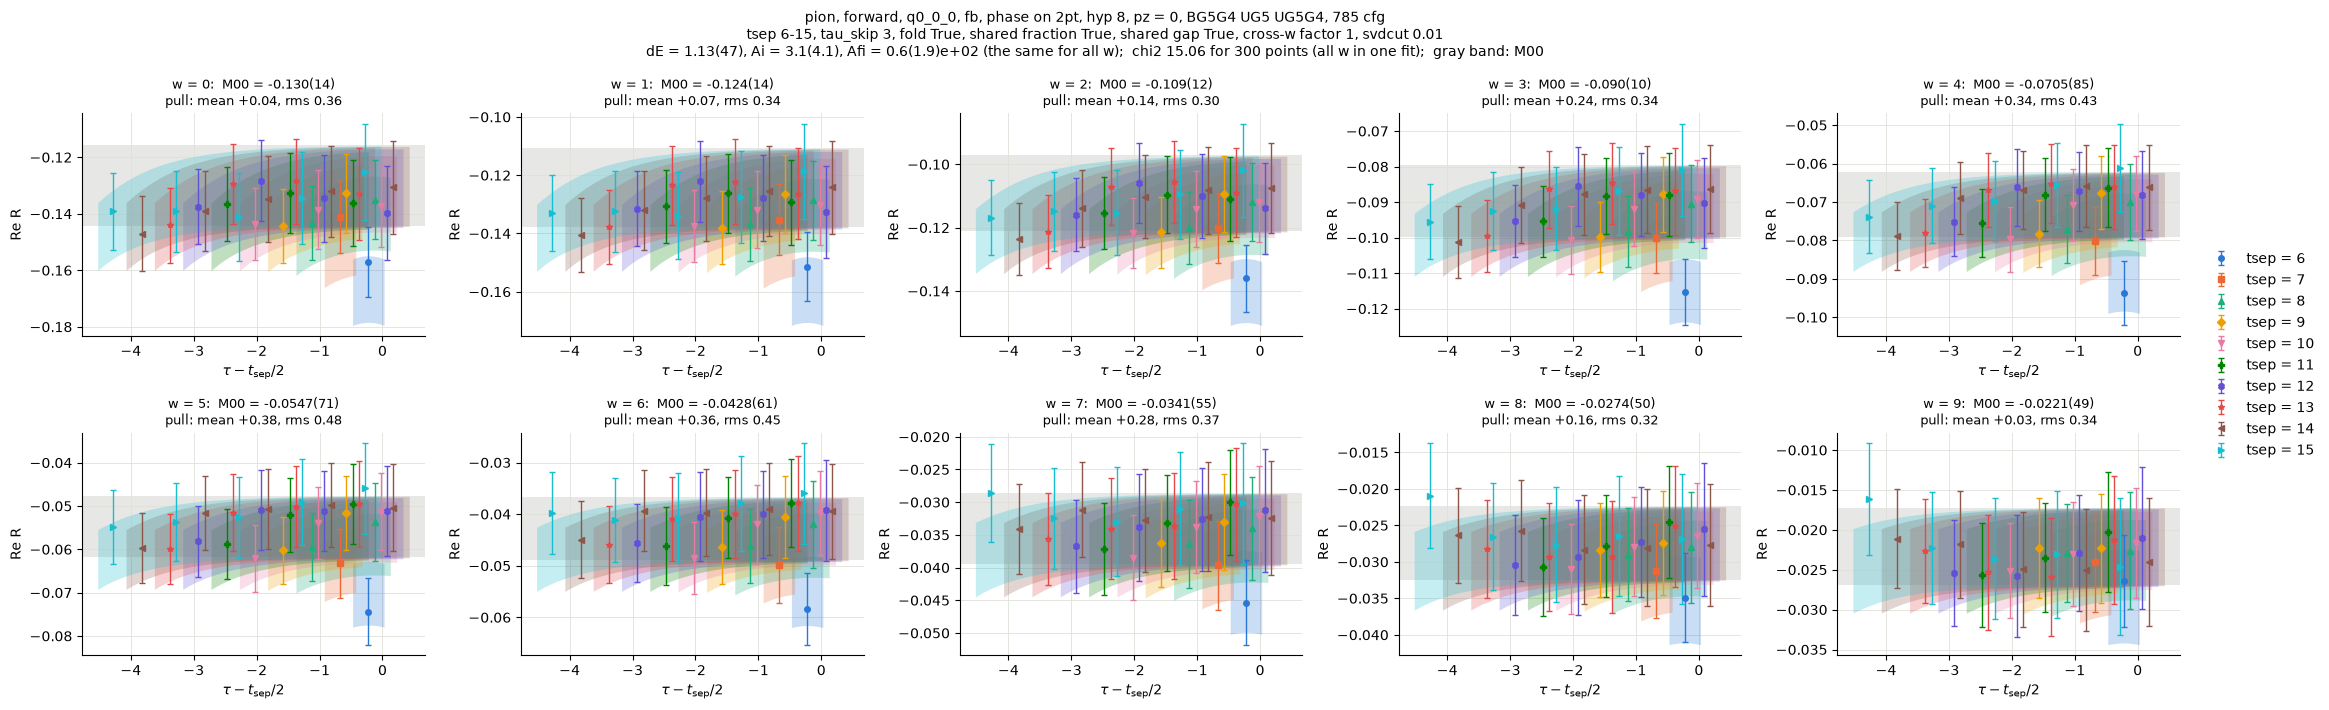

---- pz = 1, UG5 UG5G4:  pulls of the fitted points
  w  mean pull  rms pull  largest
  0      +0.01      0.19    -0.43
  1      +0.02      0.17    -0.35
  2      +0.05      0.16    +0.42
  3      +0.09      0.24    +0.51
  4      +0.13      0.37    +0.57
  5      +0.16      0.45    +0.68
  6      +0.17      0.47    +0.74
  7      +0.15      0.42    +0.78
  8      +0.12      0.34    +0.80
  9      +0.07      0.25    +0.69


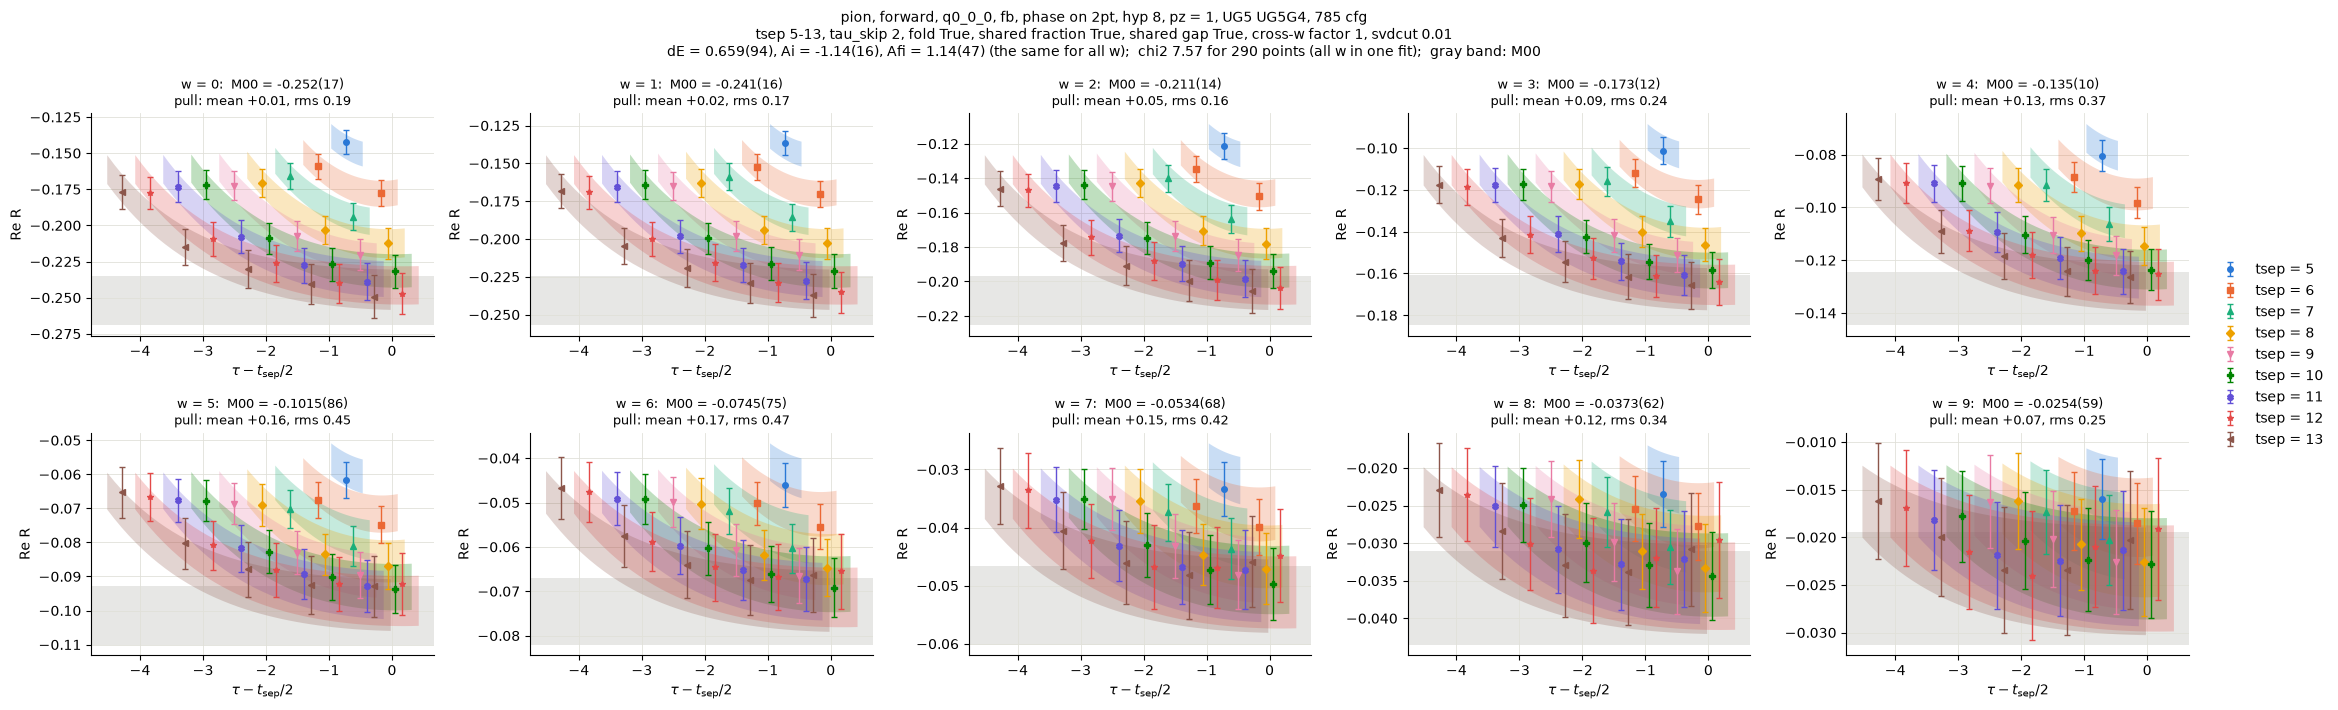

---- pz = 2, BG5 UG5G4 UG3G5:  pulls of the fitted points
  w  mean pull  rms pull  largest
  0      +0.06      0.32    +1.06
  1      +0.08      0.31    +1.04
  2      +0.11      0.30    +0.99
  3      +0.15      0.34    +0.87
  4      +0.18      0.40    -0.83
  5      +0.19      0.43    -0.92
  6      +0.16      0.42    -0.83
  7      +0.11      0.38    +0.70
  8      +0.04      0.36    +0.81
  9      -0.03      0.36    -0.85


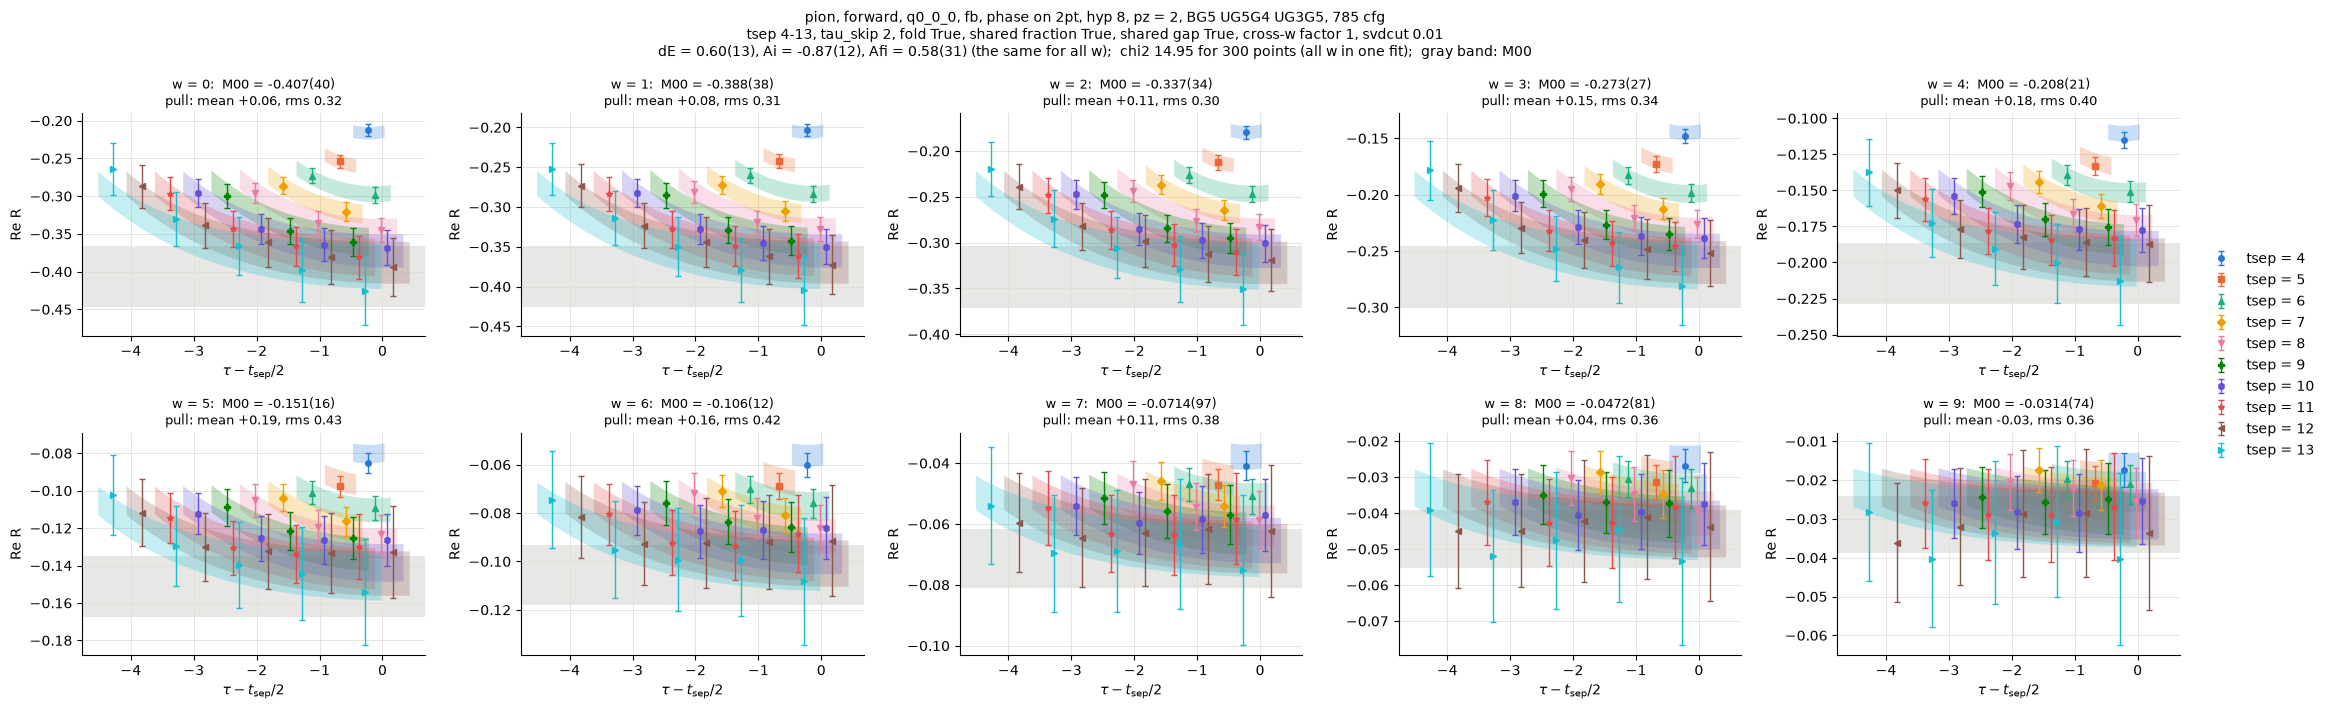

---- pz = 3, UG3G5:  pulls of the fitted points
  w  mean pull  rms pull  largest
  0      -0.05      0.60    +1.37
  1      -0.05      0.57    +1.29
  2      -0.06      0.50    +1.04
  3      -0.06      0.39    +0.73
  4      -0.04      0.33    +1.00
  5      -0.01      0.40    +1.10
  6      +0.03      0.49    -1.15
  7      +0.06      0.54    -1.19
  8      +0.09      0.55    +1.13
  9      +0.11      0.55    +1.26


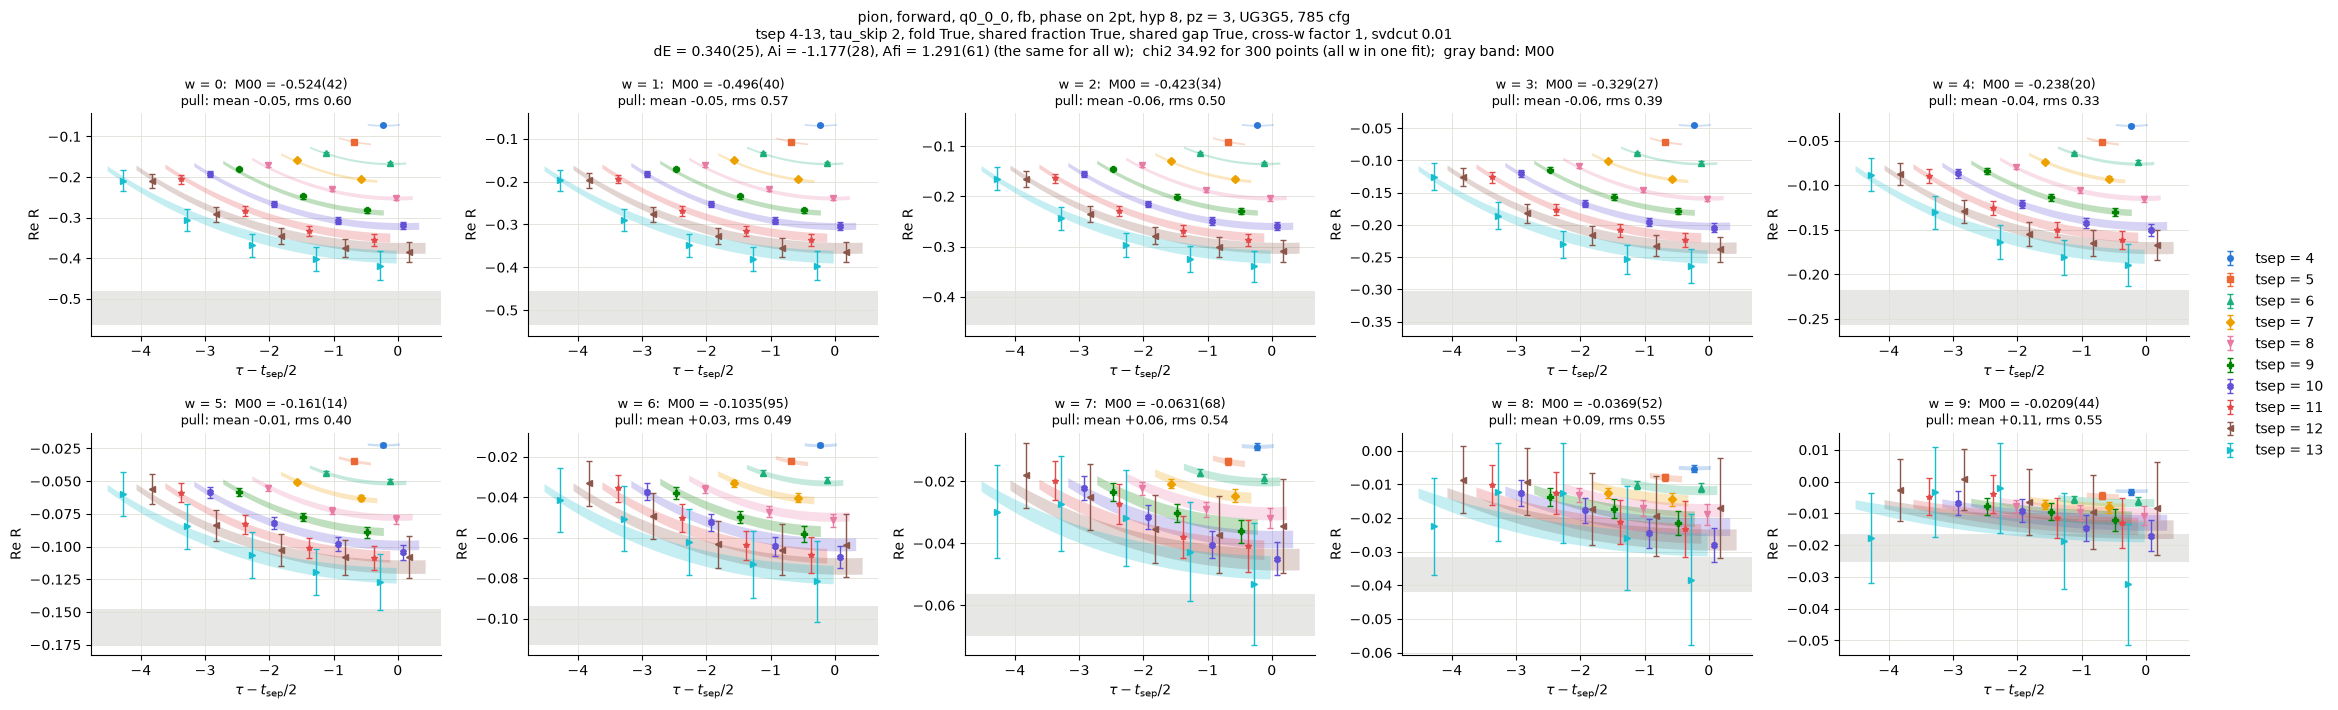

---- pz = 4, UG3G5:  pulls of the fitted points
  w  mean pull  rms pull  largest
  0      -0.19      0.82    -1.98
  1      -0.19      0.81    -1.95
  2      -0.16      0.76    -1.83
  3      -0.12      0.66    -1.54
  4      -0.07      0.56    +1.43
  5      -0.03      0.51    +1.40
  6      -0.02      0.52    +1.23
  7      -0.03      0.54    -1.23
  8      -0.06      0.54    +1.29
  9      -0.08      0.55    +1.37


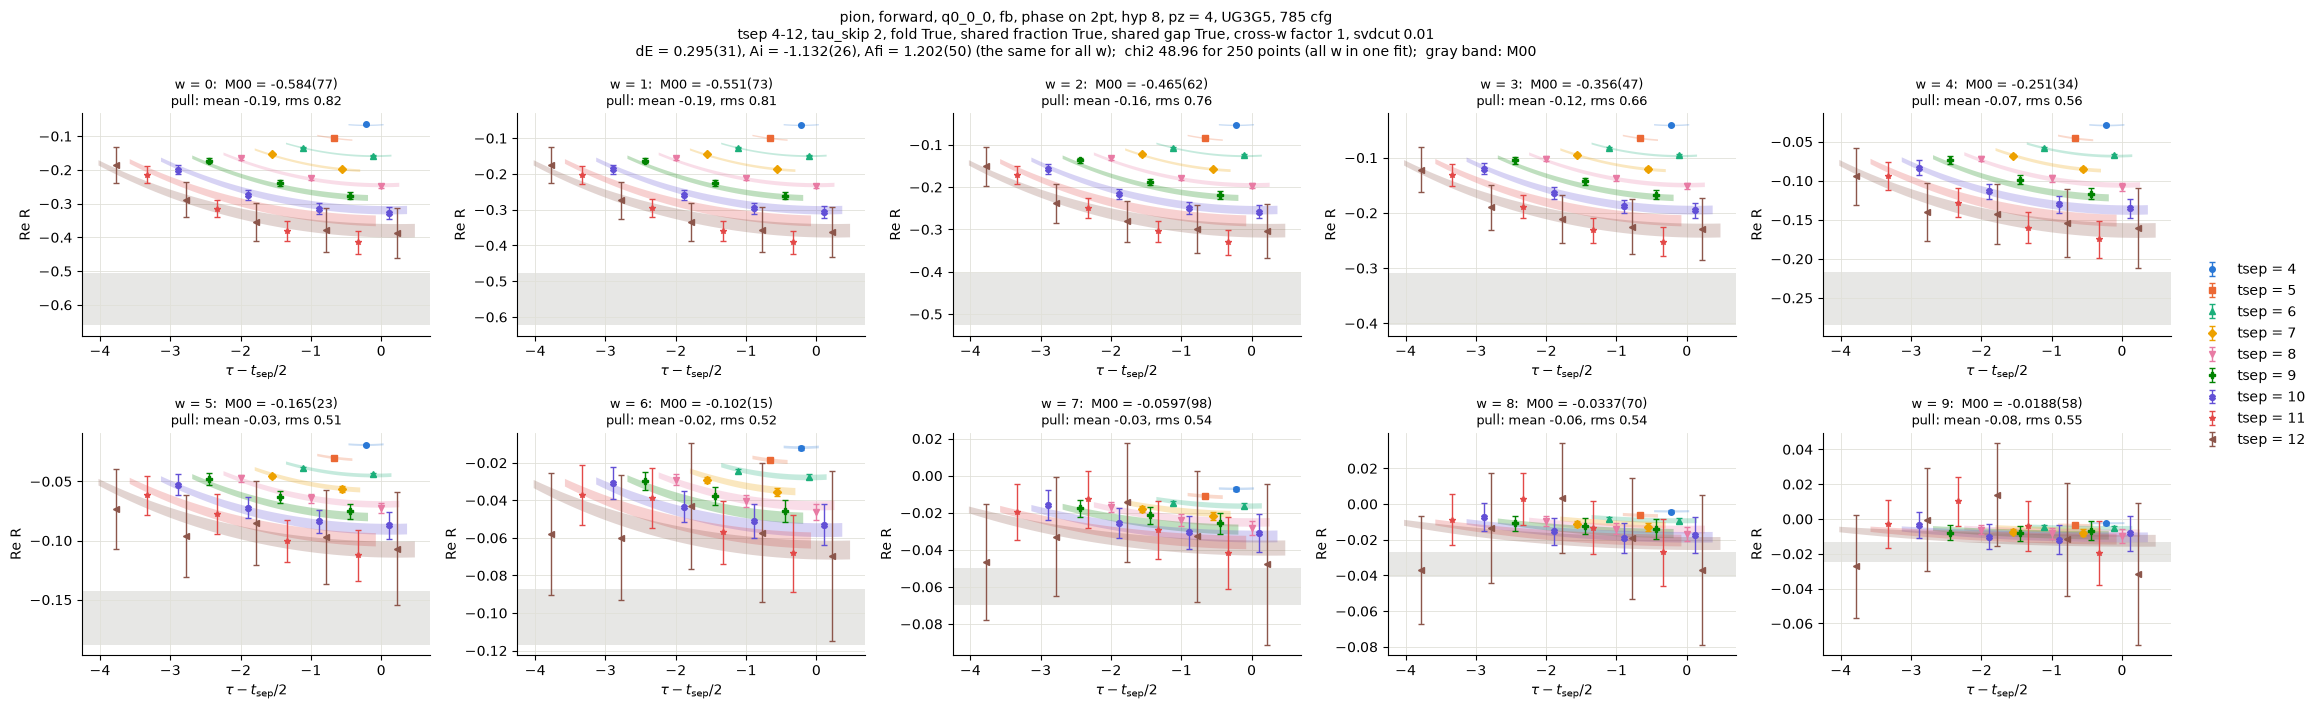

---- pz = 5, BG5G4 UG5G4:  pulls of the fitted points
  w  mean pull  rms pull  largest
  0      +0.44      0.65    +1.26
  1      +0.48      0.73    +1.30
  2      +0.60      1.01    +1.42
  3      +0.79      1.41    -1.96
  4      +0.99      1.77    -2.42
  5      +1.16      1.99    +2.65
  6      +1.27      2.07    +2.99
  7      +1.30      2.05    +3.17
  8      +1.24      1.95    +3.20
  9      +1.10      1.76    +3.08


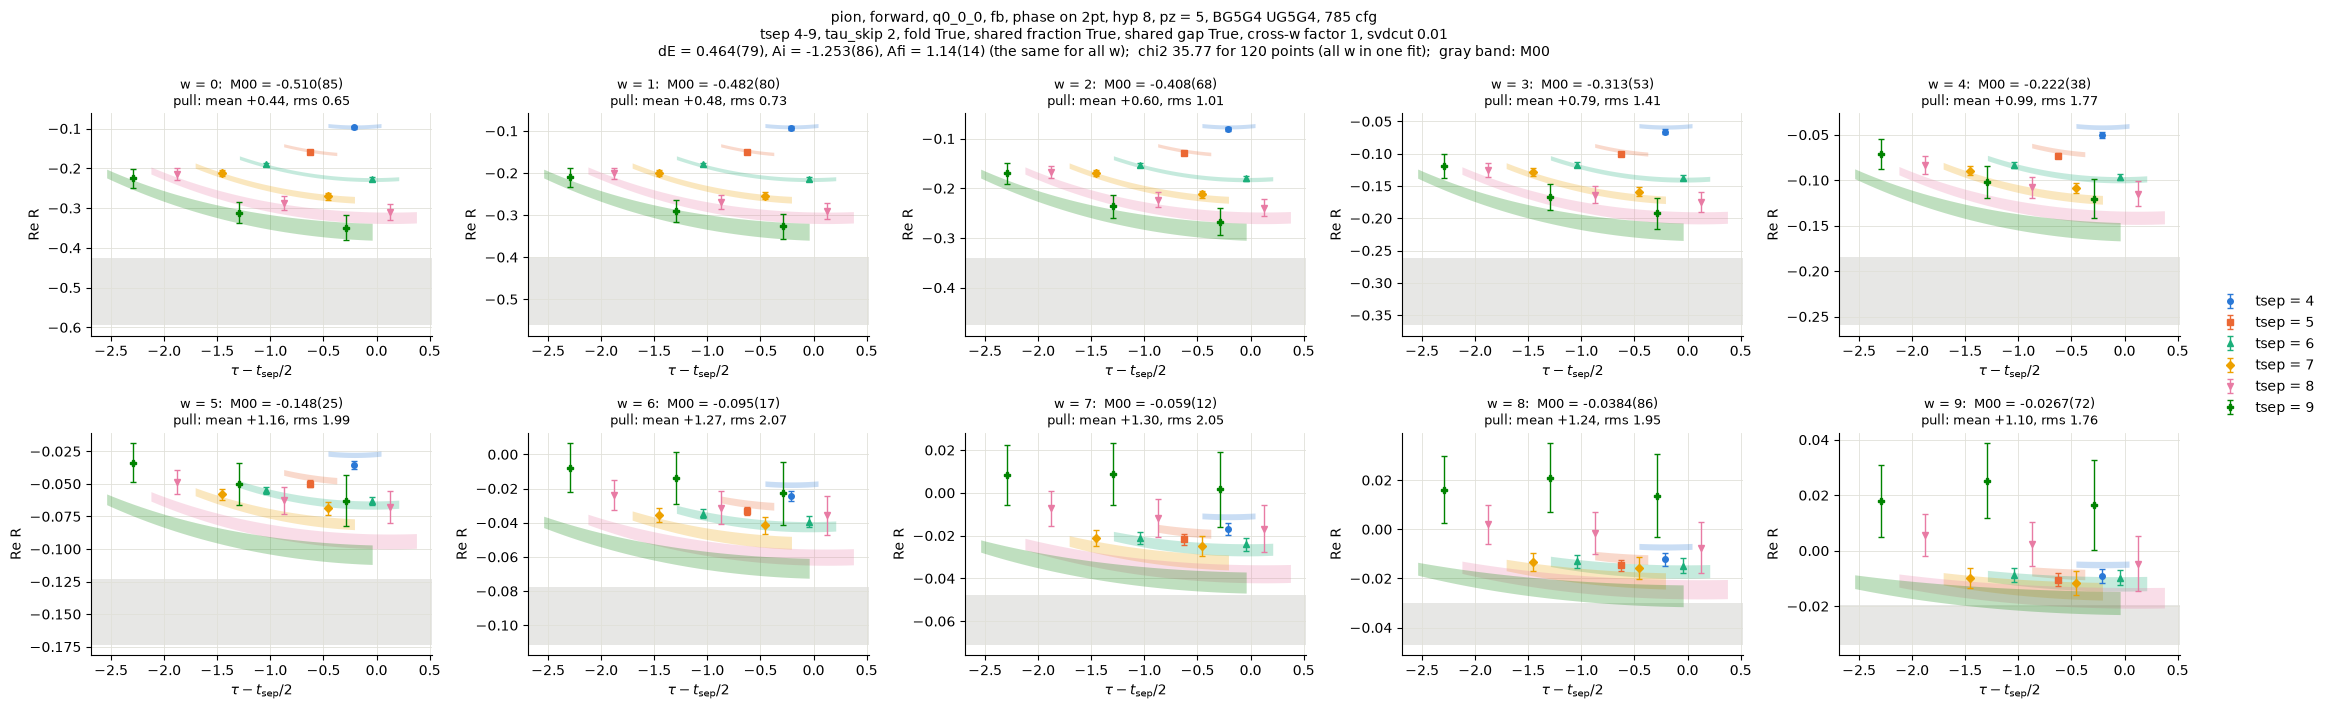

---- pz = 6, BG3G5 UG3G5:  pulls of the fitted points
  w  mean pull  rms pull  largest
  0      +0.41      0.80    +1.35
  1      +0.41      0.85    +1.41
  2      +0.39      1.01    +1.55
  3      +0.35      1.21    -1.99
  4      +0.28      1.34    -2.40
  5      +0.20      1.33    -2.48
  6      +0.12      1.28    -2.38
  7      +0.04      1.25    -2.33
  8      -0.04      1.29    -2.36
  9      -0.13      1.38    -2.38


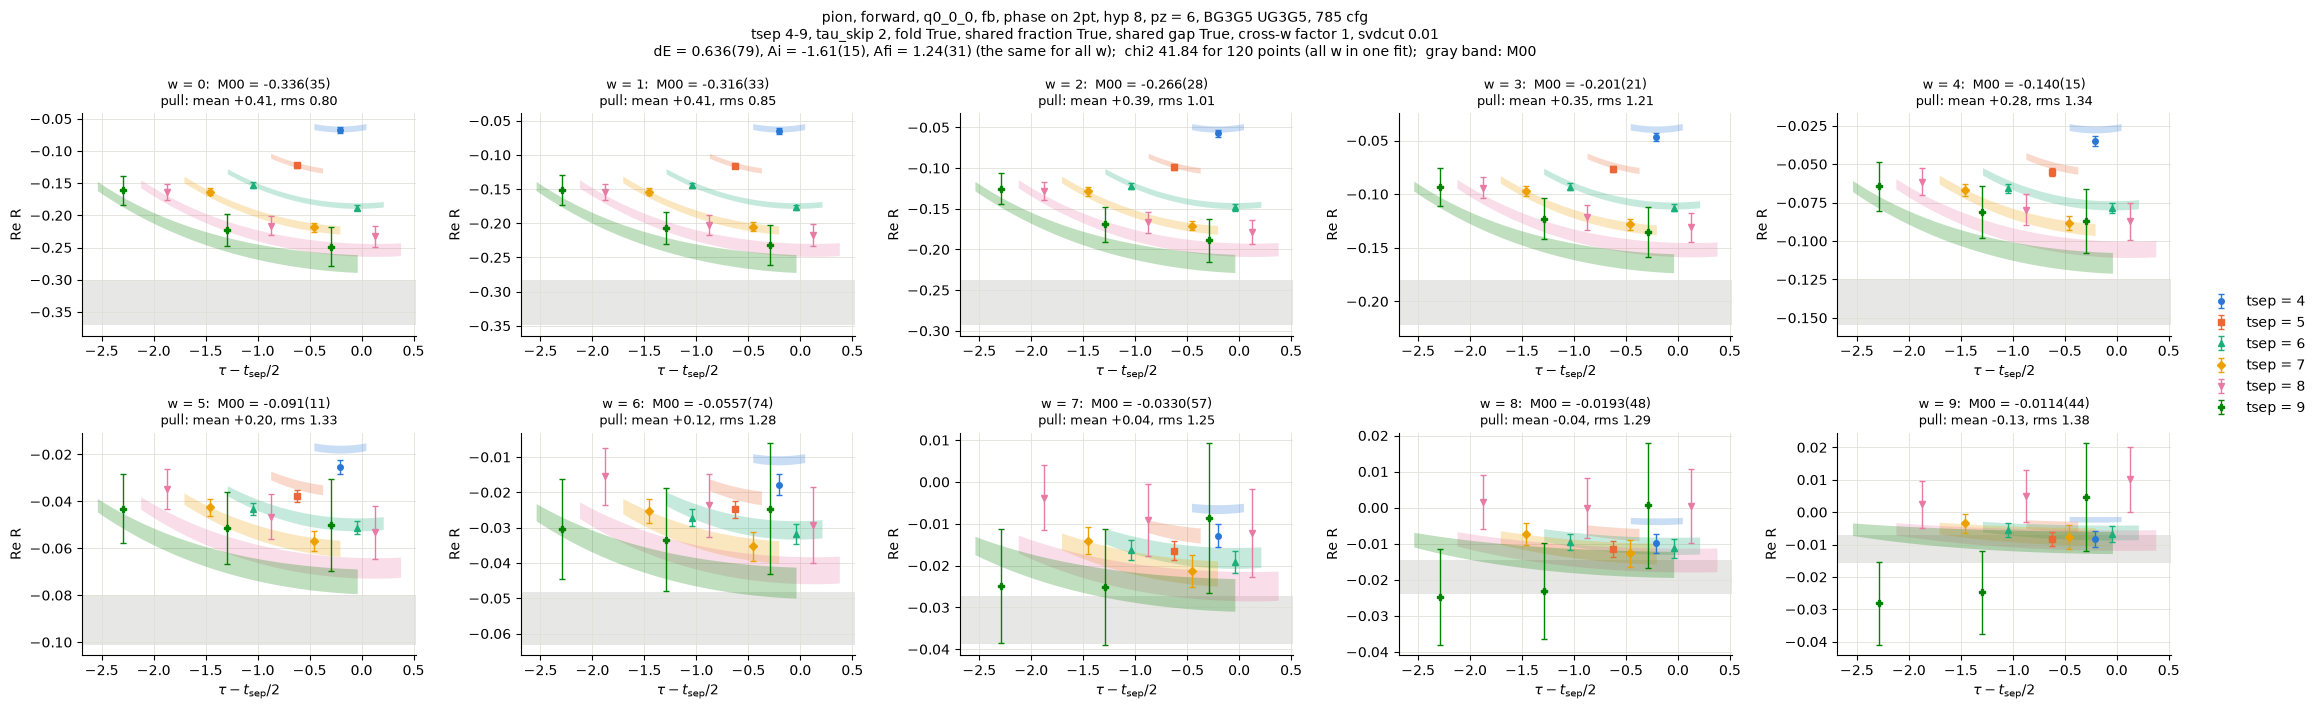

nothing is saved yet: run section 6b to save the fits you accept


In [14]:
#======== check the ratio fits of section 5: one figure per pz, one panel per w;  nothing is saved here ========
#points: the fitted Re R (folded if "fold");  colored bands: the fit curve of every jackknife sample, one band per tsep;  gray band: M00
#pull = (point - fit curve of the jackknife mean) / error of the point;  a good fit has its bands passing through the points, so pulls of size 1 or less and a mean pull near 0
#with cross_w_factor 1 and svdcut 1e-2 the chi2 is far below the number of points whatever the fit does, so look at the bands and the pulls, not at chi2
check_pz_list = fit_pz_run          #the pz to show:  the ones section 5 just fitted
check_n_col = 5                     #panels per row

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948", "#8c564b", "#17becf",
          "#7f7f7f", "#bcbd22", "#000000", "#c49c94", "#9edae5", "#ff9896", "#98df8a", "#c5b0d5", "#ffbb78", "#aec7e8"]
markers = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "p", "h", "H", "d", "8", "1", "2", "3", "4", "+"]
#check_fig[pz]: the figure of this pz, kept for section 6b
for pz in check_pz_list:
    ipz = fit_pz_list.index(pz)
    choice = fit_choice[pz]
    first, last = choice["tsep"]
    tsep_points = fit_points[pz]["tsep"]        #(n_point,)
    tau_points = fit_points[pz]["tau"]          #(n_point,)
    tsep_values = np.unique(tsep_points)
    switches = {"shared_gap": choice["shared_gap"], "shared_fraction": choice["shared_fraction"]}

    n_row = int(np.ceil(n_w / check_n_col))
    fig, axes = plt.subplots(n_row, check_n_col, figsize=(4.4 * check_n_col, 3.6 * n_row), squeeze=False)
    print(f"---- pz = {pz}, {fit_basis[ipz]}:  pulls of the fitted points")
    print(f"{'w':>3s} {'mean pull':>10s} {'rms pull':>9s} {'largest':>8s}")
    for iw, w in enumerate(fit_w_list):
        ax = axes.flat[iw]
        y_jk = fit_y_jk[pz][:, iw]                                  #(jk, n_point)
        y_mean, y_err = jk(y_jk)

        #the pulls: the curve of the fit of the jackknife mean at the fitted points
        p_mean = {}
        for name in fit_param_names:
            p_mean[name] = param_central[pz][name][iw:iw + 1]       #(1,): this w only, so its index in the model is 0
        curve = ratio_model({"tsep": tsep_points, "tau": tau_points, "iw": 0, "shared_gap": switches["shared_gap"], "shared_fraction": switches["shared_fraction"]}, p_mean)    #(n_point,)
        pull = (y_mean - curve) / y_err
        print(f"{w:3d} {pull.mean():+10.2f} {np.sqrt((pull ** 2).mean()):9.2f} {pull[np.argmax(np.abs(pull))]:+8.2f}")

        #the bands: the curve of every jackknife sample
        p_jk = {}
        for name in fit_param_names:
            p_jk[name] = param_jk[pz][name][None, :, iw, None]      #(1, jk, 1):  p_jk[name][0] is (jk, 1), so the model below gives (jk, n_tau)
        mean, err = jk(param_jk[pz]["M00"][:, iw])
        M00 = gv.gvar(mean, err)
        ax.axhspan(M00.mean - M00.sdev, M00.mean + M00.sdev, color="#e7e7e5", lw=0, zorder=0)
        for i, tsep in enumerate(tsep_values):
            on_tsep = tsep_points == tsep
            tau = tau_points[on_tsep]
            shift = 0.5 / len(tsep_values) * (i - (len(tsep_values) - 1) / 2)     #small shift so the error bars do not sit on top of each other
            #0.25 past the last points on each side, else a tsep with one point has no width
            tau_band = np.linspace(tau[0] - 0.25, tau[-1] + 0.25, 40)
            band_mean, band_err = jk(ratio_model({"tsep": tsep, "tau": tau_band, "iw": 0, "shared_gap": switches["shared_gap"], "shared_fraction": switches["shared_fraction"]}, p_jk))
            ax.fill_between(tau_band - tsep / 2 + shift, band_mean - band_err, band_mean + band_err, color=colors[i], alpha=0.25, lw=0, zorder=1)
            ax.errorbar(tau - tsep / 2 + shift, y_mean[on_tsep], y_err[on_tsep], color=colors[i], marker=markers[i], ms=4, ls="none", elinewidth=1, capsize=2, zorder=2, label=f"tsep = {tsep}")
        ax.grid(color="#e1e0d9", lw=0.6)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_xlabel(r"$\tau - t_{\rm sep}/2$")
        ax.set_ylabel("Re R")
        ax.set_title(f"w = {w}:  M00 = {M00}\npull: mean {pull.mean():+.2f}, rms {np.sqrt((pull ** 2).mean()):.2f}", fontsize=9)
    for i in range(n_w, n_row * check_n_col):
        axes.flat[i].set_visible(False)     #panels without a w

    text = {}
    for name in ["dE", "Ai", "Afi"]:
        mean, err = jk(param_jk[pz][name][:, 0])
        text[name] = str(gv.gvar(mean, err))
    if choice["shared_fraction"]:
        shared_text = f"dE = {text['dE']}, Ai = {text['Ai']}, Afi = {text['Afi']} (the same for all w)"
    elif choice["shared_gap"]:
        shared_text = f"dE = {text['dE']} (the same for all w)"
    else:
        shared_text = "each w has its own dE"
    if choice["shared_gap"] or choice["cross_w_factor"] != 0:
        chi2_text = f"chi2 {fit_chi2[pz][0]:.2f} for {fit_dof[pz][0]} points (all w in one fit)"
    else:
        chi2_text = "each w has its own fit, its chi2 is in the table of section 5"
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=10)
    fig.suptitle(f"{hadron_tag}, {frame}, {fit_q_tag}, {fit_half}, phase on {phase_attached_to}, hyp {hyp}, pz = {pz}, {fit_basis[ipz]}, {n_jk} cfg\n"
                 f"tsep {first}-{last}, tau_skip {choice['tau_skip']}, fold {choice['fold']}, shared fraction {choice['shared_fraction']}, shared gap {choice['shared_gap']}, cross-w factor {choice['cross_w_factor']:g}, svdcut {choice['svdcut']:g}\n"
                 f"{shared_text};  {chi2_text};  gray band: M00", fontsize=10)
    fig.tight_layout()
    check_fig[pz] = fig
    plt.show()
print("nothing is saved yet: run section 6b to save the fits you accept")

## 6b. Save the ratio fits?

In [ ]:
#======== save the ratio fits of section 5?  it asks for each pz, and saves that pz only if you answer y ========
#one file per pz, replaced when you save that pz again;  the file states the fitted data and every setting;  section 7 reads these files
for pz in fit_pz_run:
    assert pz in check_fig, f"pz = {pz} has no figure: run section 6a after section 5, then this cell"
for pz in fit_pz_run:
    answer = input(f"save the ratio fit of pz = {pz}? [y/N] ")
    if answer.strip().lower() in ("y", "yes"):
        ipz = fit_pz_list.index(pz)
        choice = fit_choice[pz]
        fit_file = ratio_fit_path(frame, fit_q_tag, fit_subfolder, fit_half, pz)
        if os.path.exists(fit_file):
            print("replacing", fit_file)
        os.makedirs(os.path.dirname(fit_file), exist_ok=True)
        with h5py.File(fit_file, "w") as f, h5py.File(fit_ratio_file, "r") as f_ratio:
            #results
            for name in fit_param_names:
                f[f"{name}_jk"] = param_jk[pz][name]                    #(jk, w);  a parameter shared by all w has the same number at every w
                f[f"{name}_central"] = param_central[pz][name]          #(w,)
                f[f"{name}_lsqfit_err"] = param_lsqfit_err[pz][name]    #(w,)
            f["chi2"] = fit_chi2[pz]                                    #(w,)
            f["dof"] = fit_dof[pz]                                      #(w,)
            f["Q"] = fit_Q[pz]                                          #(w,)
            f["svd_modes"] = fit_svd_modes[pz]                          #(w,): modes of the covariance raised by the svdcut
            f["n_not_converged"] = fit_n_not_converged[pz]
            f["n_fits"] = fit_n_total[pz]
            f["fit_data_jk"] = fit_y_jk[pz]                             #(jk, w, n_point): the fitted Re R, folded if fold
            f["fit_tsep"] = fit_points[pz]["tsep"]                      #(n_point,)
            f["fit_tau"] = fit_points[pz]["tau"]                        #(n_point,)
            #settings
            f["pz"] = pz
            f["basis_of_this_pz"] = fit_basis[ipz]
            f["ratio_file"] = fit_ratio_file
            f["model"] = "ratio"
            f["fit_half"] = fit_half
            f["fit_window"] = (choice["tsep"][0], choice["tsep"][1], choice["tau_skip"])    #first tsep, last tsep, tau_skip
            f["fit_range_tag"] = f"{choice['tsep'][0]}-{choice['tsep'][1]}s{choice['tau_skip']}"
            f["fold"] = choice["fold"]
            f["shared_fraction"] = choice["shared_fraction"]
            f["shared_gap"] = choice["shared_gap"]
            f["cross_w_factor"] = choice["cross_w_factor"]
            f["svdcut"] = choice["svdcut"]
            f["dE_prior"] = choice["dE_prior"]                          #(center, width)
            f["M00_prior"] = choice["M00_prior"]                        #(center, width)
            f["Ai_prior"] = choice["Ai_prior"]                          #(center, width)
            f["Afi_prior"] = choice["Afi_prior"]                        #(center, width)
            f["correlated"] = fit_correlated
            f["cov_per_sample"] = fit_cov_per_sample
            f["maxit"] = fit_maxit
            f["tol"] = fit_tol
            f["fitter"] = fit_fitter
            #what the data are, as stated in the ratio file
            for name in ["q_list", "q_tag", "subfolder", "frame", "hadron_tag", "ncfg", "cfg_list", "pz_list", "w_list", "hyp", "phase_attached_to",
                         "gevp_tag", "gevp_basis", "op_basis", "smear_names", "smear_list", "gamma_names", "t0", "t_ref", "data_sets", "data_set_ncfg", "data_set_cfg_shift"]:
                f_ratio.copy(name, f)
        print("saved", fit_file)

        #the figure of section 6a, in ratio_fit_plots/{forward, sym_q..., sym_averaged_over_q}
        fit_plot_file = os.path.join(save_dir, "ratio_fit_plots", fit_subfolder, os.path.basename(fit_file).replace(".h5", ".png"))
        os.makedirs(os.path.dirname(fit_plot_file), exist_ok=True)
        check_fig[pz].savefig(fit_plot_file, dpi=150, bbox_inches="tight")
        print("saved", fit_plot_file)
    else:
        print(f"pz = {pz}: not saved")

## 7. Single and double ratios: plots and h5 file

In [ ]:
#======== single and double ratios from the saved fits: the plots and one h5 file;  only section 0 has to be run before this cell ========
#single ratio S(pz, w) = M00(pz, w) / M00_ref(w) * E_ref / E(pz)
#double ratio D(pz, w) = [M00(pz, w) / M00(pz, w_ref)] / [M00_ref(w) / M00_ref(w_ref)]
#M00: the saved ratio fit of each pz (section 6b);  E: the central E0 of the saved 2pt fit (section 2b)
itd_pz_list = [0, 1, 2, 3, 4, 5, 6] #the pz to include;  each needs a saved ratio fit;  pz 0 has to be in when it is the reference
itd_half = "fb"                     #the half of the saved fits: "forward", "backward" or "fb"
itd_average_over_q = True           #sym only: True = the fits of the q average, False = the fits at the q of section 0
itd_ref = "pz0"                     #sym only, the reference at nu = 0: "pz0" = the P_z = 0 entry of this run (the same t), "p000" = p = (0,0,0) of the forward run (t = 0);  forward: always p = (0,0,0)
itd_w_ref = 0                       #double ratio: every matrix element is divided by its value at this w
itd_plot_err_max = 0.5              #leave out points with a larger error, so noisy points do not set the y range
itd_label = ""                      #extra text in the names of the saved file and plot;  "" = none

assert itd_ref in ["pz0", "p000"], f"itd_ref = {itd_ref}: use pz0 or p000"
if frame == "forward":
    itd_q_tag = "q0_0_0"
    itd_subfolder = "forward"
    itd_ref_used = "p000"           #forward: pz 0 is p = (0,0,0)
elif itd_average_over_q:
    itd_q_tag = "averaged_over_q"
    itd_subfolder = "sym_averaged_over_q"
    itd_ref_used = itd_ref
else:
    itd_q_tag = f"q{q[0]}_{q[1]}_{q[2]}"
    itd_subfolder = f"sym_{itd_q_tag}"
    itd_ref_used = itd_ref

#---- read the saved ratio fit of every pz
itd_fit_file = {}       #itd_fit_file[pz]: the saved ratio fit of this pz
for pz in itd_pz_list:
    itd_fit_file[pz] = ratio_fit_path(frame, itd_q_tag, itd_subfolder, itd_half, pz)
    assert os.path.exists(itd_fit_file[pz]), f"no saved ratio fit of pz = {pz}: fit it in section 5 and save it in section 6b, or take it out of itd_pz_list.  Looked for {itd_fit_file[pz]}"
with h5py.File(itd_fit_file[itd_pz_list[0]], "r") as f:
    w_values = f["w_list"][()]
    itd_cfg_list = f["cfg_list"][()]
n_jk = len(itd_cfg_list)
n_w = len(w_values)
n_pz = len(itd_pz_list)
M_jk = np.zeros((n_jk, n_w, n_pz))      #(jk, w, pz): M00 of every jackknife sample
for i, pz in enumerate(itd_pz_list):
    with h5py.File(itd_fit_file[pz], "r") as f:
        assert np.array_equal(f["cfg_list"][()], itd_cfg_list), f"pz = {pz}: the saved fit has other cfgs than pz = {itd_pz_list[0]}"
        assert np.array_equal(f["w_list"][()], w_values), f"pz = {pz}: the saved fit has other w than pz = {itd_pz_list[0]}"
        M_jk[:, :, i] = f["M00_jk"][()]

#---- read the saved 2pt fit: the central E0 of every pz
itd_pt2_file = pt2_fit_path(frame, itd_q_tag, itd_subfolder, itd_half)
assert os.path.exists(itd_pt2_file), f"no saved 2pt fit: run sections 2a and 2b.  Looked for {itd_pt2_file}"
E_central = np.zeros(n_pz)              #(pz,)
with h5py.File(itd_pt2_file, "r") as f:
    assert np.array_equal(f["cfg_list"][()], itd_cfg_list), "the 2pt fit has other cfgs than the ratio fits"
    pt2_pz_list = list(f["pz_list"][()])
    for i, pz in enumerate(itd_pz_list):
        E_central[i] = f["E_central"][pt2_pz_list.index(pz), 0]

#---- the reference at nu = 0
if frame == "sym" and itd_ref_used == "p000":
    #p = (0,0,0) of the forward run of this gevp_tag: its saved pz 0 ratio fit and its saved 2pt fit
    itd_ref_fit_file = ratio_fit_path("forward", "q0_0_0", "forward", itd_half, 0)
    itd_ref_pt2_file = pt2_fit_path("forward", "q0_0_0", "forward", itd_half)
    assert os.path.exists(itd_ref_fit_file), f"no saved forward ratio fit of pz = 0.  Looked for {itd_ref_fit_file}"
    assert os.path.exists(itd_ref_pt2_file), f"no saved forward 2pt fit.  Looked for {itd_ref_pt2_file}"
    with h5py.File(itd_ref_fit_file, "r") as f:
        assert np.array_equal(f["cfg_list"][()], itd_cfg_list), "the forward fit has other cfgs"
        assert np.array_equal(f["w_list"][()], w_values), "the forward fit has other w"
        M_ref_jk = f["M00_jk"][()][:, :, None]          #(jk, w, 1)
    with h5py.File(itd_ref_pt2_file, "r") as f:
        E_ref = f["E_central"][list(f["pz_list"][()]).index(0), 0]
else:
    #the pz 0 entry of this run
    assert 0 in itd_pz_list, "pz 0 has to be in itd_pz_list, it is the reference"
    itd_ref_fit_file = itd_fit_file[0]
    itd_ref_pt2_file = itd_pt2_file
    i_ref = itd_pz_list.index(0)
    M_ref_jk = M_jk[:, :, i_ref:i_ref + 1]              #(jk, w, 1)
    E_ref = E_central[i_ref]

#---- the ratios, sample by sample;  E_ref / E is the central value for every sample
iw_ref = list(w_values).index(itd_w_ref)
nu = 2 * np.pi / Ls * np.outer(w_values, itd_pz_list)                                                   #(w, pz)
single_jk = M_jk / M_ref_jk * (E_ref / E_central)                                                       #(jk, w, pz)
double_jk = (M_jk / M_jk[:, iw_ref:iw_ref + 1]) / (M_ref_jk / M_ref_jk[:, iw_ref:iw_ref + 1])           #(jk, w, pz)
single_mean, single_err = jk(single_jk)     #(w, pz)
double_mean, double_err = jk(double_jk)     #(w, pz)

#---- print: what went in, then the two tables
print(f"{hadron_tag}, {frame}, {itd_q_tag}, {itd_half}, {n_jk} cfg, reference {itd_ref_used}, E_ref = {E_ref:.4f}")
print(f"{'pz':>3s} {'E':>8s} {'E_ref/E':>8s}  the saved ratio fit")
for i, pz in enumerate(itd_pz_list):
    with h5py.File(itd_fit_file[pz], "r") as f:
        fit_text = f"{f['basis_of_this_pz'].asstr()[()]}, tsep {f['fit_range_tag'].asstr()[()]}, fold {f['fold'][()]}, shared fraction {f['shared_fraction'][()]}, svdcut {f['svdcut'][()]:g}"
    print(f"{pz:3d} {E_central[i]:8.4f} {E_ref / E_central[i]:8.4f}  {fit_text}")
for title, mean, err in [("single ratio", single_mean, single_err), ("double ratio", double_mean, double_err)]:
    print(title)
    print(f"{'w':>3s} " + " ".join(f"{'pz = ' + str(pz):>12s}" for pz in itd_pz_list))
    for iw, w in enumerate(w_values):
        print(f"{w:3d} " + " ".join(f"{str(gv.gvar(mean[iw, i], err[iw, i])):>12s}" for i in range(n_pz)))

#---- save the single and the double ratio
if itd_label == "":
    itd_label_text = ""
else:
    itd_label_text = "_" + itd_label
itd_name = f"itd_{frame}_{itd_q_tag}_{gevp_tag}_phase{phase_attached_to}_{itd_half}_hyp{hyp}_ncfg{ncfg}_ref{itd_ref_used}_wref{itd_w_ref}{itd_label_text}_{hadron_tag}"
itd_file = os.path.join(save_dir, "itd_data", itd_subfolder, itd_name + ".h5")
if os.path.exists(itd_file):
    print("replacing", itd_file)
os.makedirs(os.path.dirname(itd_file), exist_ok=True)
with h5py.File(itd_file, "w") as f:
    f["single_ratio_jk"] = single_jk    #(jk, w, pz): M(p, w) / M_ref(w) * E_ref / E
    f["double_ratio_jk"] = double_jk    #(jk, w, pz): [M(p, w) / M(p, w_ref)] / [M_ref(w) / M_ref(w_ref)]
    f["single_ratio_mean"] = single_mean    #(w, pz): jackknife mean
    f["single_ratio_err"] = single_err      #(w, pz): jackknife error
    f["double_ratio_mean"] = double_mean    #(w, pz)
    f["double_ratio_err"] = double_err      #(w, pz)
    f["nu"] = nu                        #(w, pz): 2 pi / Ls * pz * w
    f["E"] = E_central                  #(pz,): the central E0 of the 2pt fit
    f["E_ref"] = E_ref
    f["w_ref"] = itd_w_ref
    f["reference"] = itd_ref_used
    f["label"] = itd_label
    f["pz_list"] = itd_pz_list
    f["w_list"] = w_values
    f["cfg_list"] = itd_cfg_list
    f["frame"] = frame
    f["hadron_tag"] = hadron_tag
    f["ncfg"] = ncfg
    f["hyp"] = hyp
    f["fit_half"] = itd_half
    f["phase_attached_to"] = phase_attached_to
    f["Ls"] = Ls
    f["pt2_fit_file"] = itd_pt2_file
    f["ref_ratio_fit_file"] = itd_ref_fit_file
    f["ref_pt2_fit_file"] = itd_ref_pt2_file
    with h5py.File(itd_pt2_file, "r") as fit_in:
        for name in ["data_sets", "data_set_ncfg", "data_set_cfg_shift"]:
            fit_in.copy(name, f)                                #the data sets that were joined;  cfg_list has their cfg_shift added
        for name in ["fit_window", "n_state", "E0_prior_center", "E0_prior_width", "dE_prior", "svdcut"]:
            fit_in.copy(name, f, name=f"pt2_fit/{name}")        #what the 2pt fit used:  f["pt2_fit/fit_window"] and so on
    for pz in itd_pz_list:
        #what the ratio fit of this pz used:  f["choice/pz3/fit_window"] and so on
        f[f"choice/pz{pz}/ratio_fit_file"] = itd_fit_file[pz]
        with h5py.File(itd_fit_file[pz], "r") as fit_in:
            for name in ["basis_of_this_pz", "model", "fit_window", "fit_range_tag", "fold", "shared_fraction", "shared_gap", "cross_w_factor", "svdcut", "cov_per_sample",
                         "dE_prior", "M00_prior", "Ai_prior", "Afi_prior", "gevp_tag", "gevp_basis", "op_basis", "smear_names", "smear_list", "gamma_names", "t0", "t_ref"]:
                fit_in.copy(name, f, name=f"choice/pz{pz}/{name}")
print("saved", itd_file)

#---- plot: the single and the double ratio versus nu, one line per pz
itd_colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
itd_markers = ["o", "s", "^", "D", "v", "P", "X"]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
for ax, mean, err, title in [(axes[0], single_mean, single_err, "single ratio:  M(p, w) / M_ref(w) x E_ref / E"),
                             (axes[1], double_mean, double_err, f"double ratio:  [M(p, w) / M(p, {itd_w_ref})] / [M_ref(w) / M_ref({itd_w_ref})]")]:
    mean = np.where(err < itd_plot_err_max, mean, np.nan)
    for i, pz in enumerate(itd_pz_list):
        if pz != 0:         #pz 0 is not drawn: all its points sit at nu = 0;  its numbers are still in the table above and in the saved file
            ax.errorbar(nu[:, i], mean[:, i], err[:, i], color=itd_colors[pz], marker=itd_markers[pz], ms=5, lw=0.8, elinewidth=1, capsize=2, label=f"pz = {pz}")
    ax.axhline(1, color="#52514e", lw=0.8, ls=":")
    ax.grid(color="#e1e0d9", lw=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel(r"$\nu = P_z z$")
    ax.set_ylabel("Re")
    ax.set_title(title, fontsize=10)
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=9)
fig.suptitle(f"{hadron_tag}, {frame}, {itd_q_tag}, {itd_half}, reference {itd_ref_used}, {n_jk} cfg, {gevp_tag}{itd_label_text}", fontsize=10)
fig.tight_layout()
itd_plot_file = os.path.join(save_dir, "itd_plots", itd_subfolder, itd_name + ".png")
os.makedirs(os.path.dirname(itd_plot_file), exist_ok=True)
fig.savefig(itd_plot_file, dpi=150)
plt.show()
print("saved", itd_plot_file)